In [1]:
# =============================================================================
# QC-MDPC / PQC R-BGNN RESEARCH FRAMEWORK
# Robust, reproducible, multi-H training, locked validation/test, publication
# artifacts, statistical comparisons, topology analysis and benchmarking.
# =============================================================================

from __future__ import annotations
import os, csv, json, math, time, random, hashlib, platform, datetime, warnings
from dataclasses import dataclass, field, asdict
from typing import Any, Dict, List, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.decomposition import PCA

try:
    from scipy.stats import binomtest
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

warnings.filterwarnings("ignore")


# =============================================================================
# CONFIG
# =============================================================================

@dataclass
class ResearchConfig:
    experiment_name: str = "QCMDPC_RBGNN_N254_Research"
    seed: int = 42
    r: int = 127
    W: int = 14
    t_train: int = 6
    training_t_values: Tuple[int, ...] = (4, 5, 6, 7, 8)

    T_max: int = 12
    embed_dim: int = 64
    hidden_dim: int = 128
    dropout: float = 0.0

    syndrome_loss_weight: float = 0.05

    lr: float = 5e-4
    min_lr: float = 1e-6
    weight_decay: float = 1e-4
    gradient_clip: float = 0.5
    epochs: int = 60

    train_graphs_per_epoch: int = 8
    batches_per_graph: int = 6
    batch_size: int = 64

    validation_graphs: int = 8
    validation_frames_per_t_per_graph: int = 500
    validation_t_values: Tuple[int, ...] = (4, 5, 6, 7, 8)

    test_graphs: int = 20
    test_frames_per_t_per_graph: int = 1000
    test_t_min: int = 2
    test_t_max: int = 12

    bitflip_max_iterations: int = 12
    bitflip_threshold_fractions: Tuple[float, ...] = (0.4, 0.5, 0.6, 0.7)
    bitflip_min_flips: int = 0

    minsum_max_iterations: int = 12
    minsum_alpha: float = 0.75

    confidence_z: float = 1.96
    latency_repeats: int = 5

    pca_t: int = 6
    pca_max_frames: int = 64
    pca_max_bits: int = 12000

    failure_analysis_t: int = 7
    failure_analysis_max_frames: int = 5000

    N: int = field(init=False)
    column_degree: int = field(init=False)
    test_t_values: Tuple[int, ...] = field(init=False)
    device: str = field(init=False)

    ensemble_status: str = field(
        default="regular two-block QC-MDPC research/toy ensemble; not a claimed BIKE parameter set",
        init=False,
    )
    error_model_description: str = field(
        default="intentional fixed-weight sparse error injection for PQC syndrome decoding; not stochastic channel-noise simulation",
        init=False,
    )

    def __post_init__(self):
        self.N = 2 * self.r
        self.column_degree = self.W // 2
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.test_t_values = tuple(range(self.test_t_min, min(self.test_t_max, self.N - 1) + 1))
        if self.r <= 1:
            raise ValueError("r must be > 1")
        if not 0 < self.W <= self.r:
            raise ValueError("Require 0 < W <= r")
        if self.W % 2:
            raise ValueError("W must be even")
        if self.t_train not in self.training_t_values:
            raise ValueError("t_train must be included in training_t_values")
        if any(not 1 <= t < self.N for t in self.training_t_values):
            raise ValueError("Invalid training t")
        if any(not 1 <= t < self.N for t in self.validation_t_values):
            raise ValueError("Invalid validation t")


CONFIG = ResearchConfig()

C_BP = "#1D3557"
C_BF = "#457B9D"
C_GNN = "#E63946"
C_SAFE = "#457B9D"
C_AUX = "#9B59B6"


# =============================================================================
# REPRODUCIBILITY / SERIALIZATION
# =============================================================================

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


def json_default(obj: Any):
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if torch.is_tensor(obj):
        return obj.detach().cpu().item() if obj.ndim == 0 else obj.detach().cpu().tolist()
    if isinstance(obj, tuple):
        return list(obj)
    if isinstance(obj, set):
        return list(obj)
    if isinstance(obj, datetime.datetime):
        return obj.isoformat()
    if isinstance(obj, np.bool_):
        return bool(obj)
    raise TypeError(f"Object of type {type(obj).__name__} is not JSON serializable")


def save_json(path: str, obj: Any) -> None:
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=4, default=json_default)


def load_json(path: str) -> Any:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def array_hash(x: np.ndarray) -> str:
    return hashlib.sha256(np.ascontiguousarray(x).tobytes()).hexdigest()


def file_sha256(path: str) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def write_csv(path: str, rows: List[Dict[str, Any]]) -> None:
    if not rows:
        return
    os.makedirs(os.path.dirname(path), exist_ok=True)
    fields = sorted({k for row in rows for k in row})
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        for row in rows:
            w.writerow({
                k: json_default(v) if isinstance(v, (np.generic, np.ndarray, torch.Tensor)) else v
                for k, v in row.items()
            })


def write_manifest(root: str) -> None:
    records = []
    for dirpath, _, filenames in os.walk(root):
        for filename in filenames:
            if filename == "artifact_manifest.json":
                continue
            p = os.path.join(dirpath, filename)
            try:
                records.append({
                    "file": os.path.relpath(p, root),
                    "bytes": os.path.getsize(p),
                    "sha256": file_sha256(p),
                })
            except Exception:
                pass
    save_json(os.path.join(root, "artifact_manifest.json"), {
        "generated_at": datetime.datetime.now().isoformat(),
        "files": sorted(records, key=lambda x: x["file"]),
    })


def collect_system_metadata(config: ResearchConfig) -> Dict[str, Any]:
    out = {
        "timestamp": datetime.datetime.now().isoformat(),
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "processor": platform.processor(),
        "torch_version": torch.__version__,
        "numpy_version": np.__version__,
        "networkx_version": nx.__version__,
        "device": config.device,
        "cuda_available": torch.cuda.is_available(),
    }
    if torch.cuda.is_available():
        out.update({
            "cuda_version": torch.version.cuda,
            "gpu_name": torch.cuda.get_device_name(0),
            "gpu_count": torch.cuda.device_count(),
        })
    return out


def create_run_directory(config: ResearchConfig) -> str:
    stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    root = os.path.join(
        os.getcwd(),
        "Research_Runs_QCMDPC",
        f"{config.experiment_name}_{stamp}",
    )
    for phase in (
        "Phase_1_Topology",
        "Phase_2_Classical_Baselines",
        "Phase_3_RBGNN_Architecture",
        "Phase_4_Training",
        "Phase_5_Evaluation",
    ):
        os.makedirs(os.path.join(root, phase), exist_ok=True)
    return root


# =============================================================================
# QC-MDPC MATRIX GENERATION
# =============================================================================

def generate_circulant_block(r: int, weight: int, rng: np.random.Generator) -> np.ndarray:
    first_row = np.zeros(r, dtype=np.uint8)
    first_row[rng.choice(r, size=weight, replace=False)] = 1
    block = np.zeros((r, r), dtype=np.uint8)
    for i in range(r):
        block[i] = np.roll(first_row, i)
    return block


def is_circulant(block: np.ndarray) -> bool:
    return all(np.array_equal(block[i], np.roll(block[0], i)) for i in range(block.shape[0]))


def generate_qc_mdpc_matrix(config: ResearchConfig, rng: np.random.Generator) -> np.ndarray:
    d = config.W // 2
    H0 = generate_circulant_block(config.r, d, rng)
    H1 = generate_circulant_block(config.r, d, rng)
    H = np.hstack((H0, H1))
    assert H.shape == (config.r, config.N)
    assert np.all(H.sum(axis=1) == config.W)
    assert np.all(H.sum(axis=0) == config.column_degree)
    assert is_circulant(H0) and is_circulant(H1)
    return H


# =============================================================================
# TOPOLOGY
# =============================================================================

def exact_four_cycle_count(H: np.ndarray) -> int:
    A = H.astype(np.int64) @ H.astype(np.int64).T
    np.fill_diagonal(A, 0)
    upper = A[np.triu_indices_from(A, k=1)]
    return int(np.sum(upper * (upper - 1) // 2))


def variable_four_cycle_participation(H: np.ndarray) -> np.ndarray:
    A = H.astype(np.int64).T @ H.astype(np.int64)
    np.fill_diagonal(A, 0)
    return np.sum(A * (A - 1) // 2, axis=1).astype(np.int64)


def topology_profile(H: np.ndarray) -> Dict[str, Any]:
    row_deg = H.sum(axis=1).astype(int)
    col_deg = H.sum(axis=0).astype(int)
    scores = variable_four_cycle_participation(H)
    A = H.astype(np.int64) @ H.astype(np.int64).T
    np.fill_diagonal(A, 0)
    upper = A[np.triu_indices_from(A, k=1)]
    values, counts = np.unique(upper, return_counts=True)
    r = H.shape[0]
    return {
        "N": int(H.shape[1]),
        "r": int(r),
        "W": int(row_deg.mean()),
        "column_degree": int(col_deg.mean()),
        "row_degree_min": int(row_deg.min()),
        "row_degree_max": int(row_deg.max()),
        "column_degree_min": int(col_deg.min()),
        "column_degree_max": int(col_deg.max()),
        "edge_count": int(H.sum()),
        "matrix_density": float(H.mean()),
        "exact_4_cycles": exact_four_cycle_count(H),
        "variable_4cycle_participation_mean": float(scores.mean()),
        "variable_4cycle_participation_std": float(scores.std()),
        "variable_4cycle_participation_max": int(scores.max()),
        "cn_overlap_spectrum": {str(int(v)): int(c) for v, c in zip(values, counts)},
        "block_0_circulant": bool(is_circulant(H[:, :r])),
        "block_1_circulant": bool(is_circulant(H[:, r:])),
    }


def structural_certificate(H: np.ndarray, config: ResearchConfig) -> Dict[str, Any]:
    p = topology_profile(H)
    checks = {
        "shape_correct": bool(H.shape == (config.r, config.N)),
        "row_regular": bool(np.all(H.sum(axis=1) == config.W)),
        "column_regular": bool(np.all(H.sum(axis=0) == config.column_degree)),
        "edge_identity": bool(H.sum() == config.r * config.W),
        "density_identity": bool(np.isclose(H.mean(), config.W / config.N)),
        "block_0_circulant": bool(p["block_0_circulant"]),
        "block_1_circulant": bool(p["block_1_circulant"]),
    }
    return {
        "all_checks_passed": bool(all(checks.values())),
        "checks": checks,
        "analytical_identities": {
            "N_equals_2r": bool(config.N == 2 * config.r),
            "E_equals_rW": bool(H.sum() == config.r * config.W),
            "column_degree_equals_W_over_2": bool(config.column_degree == config.W // 2),
            "density_equals_W_over_N": bool(np.isclose(H.mean(), config.W / config.N)),
        },
        "topology": p,
    }


# =============================================================================
# GRAPH REPRESENTATION
# =============================================================================

def build_graph(H: np.ndarray, device: torch.device) -> Dict[str, Any]:
    Ht = torch.tensor(H, dtype=torch.float32, device=device)
    r_idx, n_idx = torch.where(Ht > 0)
    r_idx, n_idx = r_idx.long(), n_idx.long()
    r, N, E = H.shape[0], H.shape[1], int(r_idx.numel())
    W = int(H.sum(axis=1)[0])
    expected = torch.arange(r, device=device).repeat_interleave(W)
    if not torch.equal(r_idx, expected):
        raise RuntimeError("H edges are not ordered by check node")
    return {"H": Ht, "r_idx": r_idx, "n_idx": n_idx, "r": r, "N": N, "E": E, "W": W}


# =============================================================================
# ERROR / SYNDROME GENERATION
# =============================================================================

def sample_fixed_weight_errors(batch_size: int, N: int, t: int, device: torch.device) -> torch.Tensor:
    scores = torch.rand(batch_size, N, device=device)
    idx = torch.topk(scores, k=t, dim=1, largest=False, sorted=False).indices
    errors = torch.zeros(batch_size, N, dtype=torch.float32, device=device)
    errors.scatter_(1, idx, 1.0)
    return errors


def generate_syndromes(errors: torch.Tensor, H: torch.Tensor) -> torch.Tensor:
    return torch.remainder(errors @ H.T, 2.0)


def sample_fixed_weight_errors_numpy(
    rng: np.random.Generator,
    count: int,
    N: int,
    t: int,
) -> np.ndarray:
    errors = np.zeros((count, N), dtype=np.uint8)
    for i in range(count):
        errors[i, rng.choice(N, size=t, replace=False)] = 1
    return errors


def save_locked_graph(
    graph_dir: str,
    H: np.ndarray,
    errors_by_t: Dict[int, np.ndarray],
    syndromes_by_t: Dict[int, np.ndarray],
    config: ResearchConfig,
) -> None:
    os.makedirs(graph_dir, exist_ok=True)
    np.save(os.path.join(graph_dir, "H.npy"), H)
    payload = {"H": H}
    for t, x in errors_by_t.items():
        payload[f"errors_t{t}"] = np.packbits(x, axis=1)
    for t, x in syndromes_by_t.items():
        payload[f"syndromes_t{t}"] = np.packbits(x, axis=1)
    np.savez_compressed(os.path.join(graph_dir, "locked_dataset.npz"), **payload)
    save_json(os.path.join(graph_dir, "topology.json"), topology_profile(H))
    save_json(
        os.path.join(graph_dir, "structural_certificate.json"),
        structural_certificate(H, config),
    )


def create_locked_graph_suite(
    config: ResearchConfig,
    seed: int,
    graph_count: int,
    t_values: Tuple[int, ...],
    frames_per_t: int,
    save_dir: str,
    prefix: str,
) -> List[Dict[str, Any]]:
    rng = np.random.default_rng(seed)
    device = torch.device(config.device)
    suite, index = [], []
    os.makedirs(save_dir, exist_ok=True)

    for graph_id in range(graph_count):
        H = generate_qc_mdpc_matrix(config, rng)
        errors_by_t, syndromes_by_t, datasets = {}, {}, {}

        for t in t_values:
            e = sample_fixed_weight_errors_numpy(rng, frames_per_t, config.N, t)
            s = np.remainder(
                e.astype(np.int64) @ H.astype(np.int64).T,
                2,
            ).astype(np.uint8)
            assert np.all(e.sum(axis=1) == t)
            errors_by_t[t] = e
            syndromes_by_t[t] = s
            datasets[t] = {
                "errors": torch.tensor(e, dtype=torch.float32, device=device),
                "syndromes": torch.tensor(s, dtype=torch.float32, device=device),
            }

        graph_dir = os.path.join(save_dir, f"{prefix}_graph_{graph_id:03d}")
        save_locked_graph(graph_dir, H, errors_by_t, syndromes_by_t, config)
        suite.append({
            "graph_id": graph_id,
            "H_numpy": H,
            "graph": build_graph(H, device),
            "datasets": datasets,
        })
        index.append({
            "graph_id": graph_id,
            "H_sha256": array_hash(H),
            "directory": os.path.relpath(graph_dir, save_dir),
            "topology": topology_profile(H),
        })

    save_json(
        os.path.join(save_dir, f"{prefix}_suite_index.json"),
        {
            "graph_count": graph_count,
            "t_values": list(t_values),
            "frames_per_t": frames_per_t,
            "graphs": index,
        },
    )
    return suite


# =============================================================================
# SANITY / STATISTICS
# =============================================================================

def wilson_interval(failures: int, trials: int, z: float = 1.96) -> Tuple[float, float]:
    if trials <= 0:
        return 0.0, 0.0
    p = failures / trials
    den = 1.0 + z * z / trials
    centre = (p + z * z / (2 * trials)) / den
    radius = z * math.sqrt(
        p * (1 - p) / trials + z * z / (4 * trials * trials)
    ) / den
    return max(0.0, centre - radius), min(1.0, centre + radius)


def compute_metrics(
    predictions: torch.Tensor,
    truth: torch.Tensor,
    syndromes: Optional[torch.Tensor] = None,
    H: Optional[torch.Tensor] = None,
) -> Dict[str, Any]:
    err = predictions != truth
    frame_fail = err.any(dim=1)
    ff = int(frame_fail.sum().item())
    fc = int(frame_fail.numel())
    bf = int(err.sum().item())
    bc = int(err.numel())
    dfr = ff / max(fc, 1)
    ber = bf / max(bc, 1)
    dlo, dhi = wilson_interval(ff, fc)
    blo, bhi = wilson_interval(bf, bc)
    out = {
        "dfr": float(dfr),
        "dfr_ci_low": float(dlo),
        "dfr_ci_high": float(dhi),
        "ber": float(ber),
        "ber_ci_low": float(blo),
        "ber_ci_high": float(bhi),
        "frame_failures": ff,
        "frame_count": fc,
        "bit_failures": bf,
        "bit_count": bc,
        "mean_residual_bit_errors": float(err.sum(dim=1).float().mean().item()),
    }
    if syndromes is not None and H is not None:
        pred_synd = torch.remainder(predictions @ H.T, 2.0)
        s_err = pred_synd != syndromes
        out["syndrome_failure_rate"] = float(s_err.any(dim=1).float().mean().item())
        out["mean_residual_syndrome_weight"] = float(s_err.sum(dim=1).float().mean().item())
    return out


def exact_mcnemar_pvalue(b: int, c: int) -> float:
    n = int(b + c)
    if n <= 0:
        return 1.0
    k = min(int(b), int(c))
    if SCIPY_AVAILABLE:
        try:
            return float(binomtest(k, n=n, p=0.5, alternative="two-sided").pvalue)
        except Exception:
            pass
    pk = math.exp(
        math.lgamma(n + 1)
        - math.lgamma(k + 1)
        - math.lgamma(n - k + 1)
        - n * math.log(2.0)
    )
    tail = pk
    prob = pk
    for i in range(k, 0, -1):
        prob *= i / (n - i + 1)
        tail += prob
    return float(min(1.0, 2.0 * tail))


def paired_comparison(
    pred_a: torch.Tensor,
    pred_b: torch.Tensor,
    truth: torch.Tensor,
) -> Dict[str, Any]:
    fail_a = (pred_a != truth).any(dim=1)
    fail_b = (pred_b != truth).any(dim=1)
    b = int((fail_a & ~fail_b).sum().item())
    c = int((~fail_a & fail_b).sum().item())
    return {
        "A_failure_B_success": b,
        "A_success_B_failure": c,
        "discordant_pairs": b + c,
        "mcnemar_exact_pvalue": exact_mcnemar_pvalue(b, c),
        "paired_failure_rate_delta": float(
            fail_a.float().mean().item() - fail_b.float().mean().item()
        ),
    }


# =============================================================================
# BIT-FLIPPING BASELINE
# =============================================================================

@torch.no_grad()
def run_bit_flipping(
    syndromes: torch.Tensor,
    H: torch.Tensor,
    max_iterations: int,
    threshold: int,
    min_flips: int = 0,
) -> Dict[str, torch.Tensor]:
    B, N = syndromes.shape[0], H.shape[1]
    estimate = torch.zeros(B, N, dtype=torch.float32, device=H.device)
    residual = syndromes.clone()
    first_zero = torch.full(
        (B,),
        float(max_iterations + 1),
        dtype=torch.float32,
        device=H.device,
    )
    found = torch.zeros(B, dtype=torch.bool, device=H.device)
    history = []

    for iteration in range(max_iterations):
        rw = residual.sum(dim=1)
        newly = (rw == 0) & ~found
        first_zero[newly] = float(iteration)
        found |= newly
        history.append(float(rw.mean().item()))
        if found.all():
            break

        unsatisfied = residual @ H
        flips = unsatisfied >= threshold

        if min_flips > 0:
            inactive = flips.sum(dim=1) < min_flips
            if inactive.any():
                best = torch.argmax(unsatisfied, dim=1)
                rows = torch.where(inactive)[0]
                flips[rows, best[rows]] = True

        estimate = torch.remainder(estimate + flips.float(), 2.0)
        residual = torch.remainder(syndromes - estimate @ H.T, 2.0)

    final_zero = (residual.sum(dim=1) == 0) & ~found
    first_zero[final_zero] = float(len(history))

    return {
        "predictions": estimate,
        "residual_syndrome": residual,
        "syndrome_iterations": first_zero,
        "syndrome_decay": torch.tensor(history, dtype=torch.float32),
    }


# =============================================================================
# SYNDROME-DOMAIN MIN-SUM HEURISTIC
# =============================================================================

@torch.no_grad()
def run_syndrome_minsum(
    syndromes: torch.Tensor,
    H: torch.Tensor,
    max_iterations: int,
    alpha: float,
) -> Dict[str, torch.Tensor]:
    B = syndromes.shape[0]
    r = H.shape[0]
    r_idx, n_idx = torch.where(H > 0)
    E = int(r_idx.numel())
    W = int(H.sum(dim=1)[0].item())

    expected = torch.arange(r, device=H.device).repeat_interleave(W)
    if not torch.equal(r_idx, expected):
        raise RuntimeError("H edge ordering incompatible with Min-Sum heuristic")

    channel_llr = W / 2.0 - syndromes @ H
    v2c = channel_llr[:, n_idx].reshape(B, r, W)
    c2v = torch.zeros_like(v2c)

    first_zero = torch.full(
        (B,),
        float(max_iterations + 1),
        dtype=torch.float32,
        device=H.device,
    )
    found = torch.zeros(B, dtype=torch.bool, device=H.device)
    history = []

    for iteration in range(max_iterations):
        total = channel_llr.clone()
        total.index_add_(1, n_idx, c2v.reshape(B, E))
        current = (total < 0).float()
        residual = torch.remainder(current @ H.T + syndromes, 2.0)
        rw = residual.sum(dim=1)
        history.append(float(rw.mean().item()))

        newly = (rw == 0) & ~found
        first_zero[newly] = float(iteration)
        found |= newly
        if found.all():
            break

        abs_v2c = torch.abs(v2c) + 1e-8
        sign_v2c = torch.where(v2c >= 0, torch.ones_like(v2c), -torch.ones_like(v2c))
        two_min = torch.topk(abs_v2c, k=2, dim=2, largest=False)
        min1, min2 = two_min.values[:, :, 0], two_min.values[:, :, 1]
        min1_pos = two_min.indices[:, :, 0]
        positions = torch.arange(W, device=H.device).view(1, 1, W)
        magnitude = torch.where(
            positions == min1_pos.unsqueeze(-1),
            min2.unsqueeze(-1),
            min1.unsqueeze(-1),
        )
        sign_excl = torch.prod(sign_v2c, dim=2, keepdim=True) * sign_v2c
        syndrome_sign = (1.0 - 2.0 * syndromes).unsqueeze(-1)
        c2v = alpha * sign_excl * syndrome_sign * magnitude

        total = channel_llr.clone()
        total.index_add_(1, n_idx, c2v.reshape(B, E))
        v2c = total[:, n_idx].reshape(B, r, W) - c2v

    final_llr = channel_llr.clone()
    final_llr.index_add_(1, n_idx, c2v.reshape(B, E))
    predictions = (final_llr < 0).float()
    final_syndrome = torch.remainder(predictions @ H.T, 2.0)
    residual = torch.remainder(final_syndrome + syndromes, 2.0)
    final_zero = (residual.sum(dim=1) == 0) & ~found
    first_zero[final_zero] = float(len(history))

    return {
        "predictions": predictions,
        "residual_syndrome": residual,
        "syndrome_iterations": first_zero,
        "syndrome_decay": torch.tensor(history, dtype=torch.float32),
    }


# =============================================================================
# R-BGNN
# =============================================================================

class RecurrentBGNN(nn.Module):
    def __init__(self, config: ResearchConfig):
        super().__init__()
        D, H = config.embed_dim, config.hidden_dim
        self.config = config

        self.variable_initializer = nn.Sequential(
            nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D)
        )
        self.check_initializer = nn.Sequential(
            nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D)
        )
        self.v2c_mlp = nn.Sequential(
            nn.Linear(2 * D, H), nn.SiLU(), nn.Linear(H, D), nn.SiLU()
        )
        self.c2v_mlp = nn.Sequential(
            nn.Linear(2 * D, H), nn.SiLU(), nn.Linear(H, D), nn.SiLU()
        )
        self.check_gru = nn.GRUCell(D, D)
        self.variable_gru = nn.GRUCell(D, D)
        self.dropout = nn.Dropout(config.dropout)
        self.readout = nn.Sequential(
            nn.Linear(D, D // 2), nn.SiLU(), nn.Linear(D // 2, 1)
        )

    def forward(
        self,
        syndrome: torch.Tensor,
        graph: Dict[str, Any],
        return_embeddings: bool = False,
    ):
        H = graph["H"]
        r_idx = graph["r_idx"]
        n_idx = graph["n_idx"]
        B = syndrome.shape[0]
        r, N, D, E = H.shape[0], H.shape[1], self.config.embed_dim, graph["E"]

        variable_degree = H.sum(dim=0).clamp_min(1.0)
        variable_signal = (syndrome @ H) / variable_degree.unsqueeze(0)
        v_feat = self.variable_initializer(variable_signal.unsqueeze(-1))
        c_feat = self.check_initializer(syndrome.unsqueeze(-1))

        edge_c_idx = r_idx.view(1, E, 1).expand(B, E, D)
        edge_v_idx = n_idx.view(1, E, 1).expand(B, E, D)
        logits_list = []

        for _ in range(self.config.T_max):
            edge_v = v_feat[:, n_idx, :]
            edge_c = c_feat[:, r_idx, :]
            m_v2c = self.dropout(
                self.v2c_mlp(torch.cat((edge_v, edge_c), dim=-1))
            )
            agg_c = torch.zeros(B, r, D, dtype=v_feat.dtype, device=v_feat.device)
            agg_c.scatter_add_(1, edge_c_idx, m_v2c)
            c_feat = self.check_gru(
                agg_c.reshape(-1, D),
                c_feat.reshape(-1, D),
            ).reshape(B, r, D)

            edge_c = c_feat[:, r_idx, :]
            edge_v = v_feat[:, n_idx, :]
            m_c2v = self.dropout(
                self.c2v_mlp(torch.cat((edge_c, edge_v), dim=-1))
            )
            agg_v = torch.zeros(B, N, D, dtype=v_feat.dtype, device=v_feat.device)
            agg_v.scatter_add_(1, edge_v_idx, m_c2v)
            v_feat = self.variable_gru(
                agg_v.reshape(-1, D),
                v_feat.reshape(-1, D),
            ).reshape(B, N, D)

            logits_list.append(self.readout(v_feat).squeeze(-1))

        return (logits_list, v_feat) if return_embeddings else logits_list


# =============================================================================
# LOSS
# =============================================================================

def differentiable_syndrome_probability(
    probabilities: torch.Tensor,
    H: torch.Tensor,
) -> torch.Tensor:
    values = []
    for i in range(H.shape[0]):
        idx = torch.where(H[i] > 0)[0]
        p = probabilities[:, idx]
        values.append(torch.clamp(
            (1.0 - torch.prod(1.0 - 2.0 * p, dim=1)) / 2.0,
            1e-6,
            1.0 - 1e-6,
        ))
    return torch.stack(values, dim=1)


def sparse_weighted_bce(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    pos = targets.sum(dim=1).clamp_min(1.0)
    neg = targets.shape[1] - pos
    pos_weight = neg / pos
    weights = torch.where(
        targets > 0.5,
        pos_weight.unsqueeze(1),
        torch.ones_like(targets),
    )
    return F.binary_cross_entropy_with_logits(
        logits,
        targets,
        weight=weights,
        reduction="mean",
    )


def research_loss(
    logits_list: List[torch.Tensor],
    targets: torch.Tensor,
    syndrome: torch.Tensor,
    H: torch.Tensor,
    syndrome_weight: float,
):
    T = len(logits_list)
    step_weights = torch.linspace(
        0.5, 1.5, T, device=targets.device
    )
    step_weights /= step_weights.sum()

    bce_total = torch.zeros((), device=targets.device)
    syndrome_total = torch.zeros((), device=targets.device)

    for w, logits in zip(step_weights, logits_list):
        bce = sparse_weighted_bce(logits, targets)
        syn_prob = differentiable_syndrome_probability(torch.sigmoid(logits), H)
        syn_loss = F.binary_cross_entropy(syn_prob, syndrome, reduction="mean")
        bce_total += w * bce
        syndrome_total += w * syn_loss

    total = bce_total + syndrome_weight * syndrome_total
    return total, {
        "total": float(total.detach().item()),
        "bce": float(bce_total.detach().item()),
        "syndrome": float(syndrome_total.detach().item()),
    }


def count_parameters(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


# =============================================================================
# PHASE 1 PLOT
# =============================================================================

def plot_topology(H: np.ndarray, save_path: str) -> None:
    p = topology_profile(H)
    fig = plt.figure(figsize=(20, 12), constrained_layout=True)
    fig.suptitle(
        f"QC-MDPC Research Ensemble Topology (N={H.shape[1]}, r={H.shape[0]}, W={p['W']}, d={p['column_degree']})",
        fontsize=18,
        fontweight="bold",
    )

    ax1 = fig.add_subplot(221)
    ax1.spy(H, markersize=1.1, color="#2C3E50")
    ax1.set_title("Parity-Check Matrix Sparsity", fontweight="bold")
    ax1.set_xlabel("Variable Nodes")
    ax1.set_ylabel("Check Nodes")

    ax2 = fig.add_subplot(222)
    A = H.astype(np.int64) @ H.astype(np.int64).T
    np.fill_diagonal(A, 0)
    upper = A[np.triu_indices_from(A, k=1)]
    counts = np.bincount(upper.astype(int))
    ax2.bar(np.arange(len(counts)), counts, color=C_AUX, edgecolor="black", alpha=0.85)
    ax2.set_title("Check-Node Intersection Spectrum", fontweight="bold")
    ax2.set_xlabel("Shared Variable Nodes")
    ax2.set_ylabel("Frequency")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)

    ax3 = fig.add_subplot(223)
    c1 = c2 = None
    for i in range(H.shape[0]):
        hit = False
        for j in range(i + 1, H.shape[0]):
            if A[i, j] >= 2:
                c1, c2 = i, j
                hit = True
                break
        if hit:
            break

    if c1 is None:
        c_idx = list(range(min(12, H.shape[0])))
        v_idx = list(range(min(24, H.shape[1])))
    else:
        shared = np.where((H[c1] == 1) & (H[c2] == 1))[0][:2].tolist()
        c_idx = list(dict.fromkeys([c1, c2] + list(range(H.shape[0]))))[:15]
        v_idx = list(dict.fromkeys(shared + list(range(H.shape[1]))))[:30]

    G = nx.Graph()
    v_nodes = [f"V{x}" for x in v_idx]
    c_nodes = [f"C{x}" for x in c_idx]
    G.add_nodes_from(v_nodes, bipartite=0)
    G.add_nodes_from(c_nodes, bipartite=1)
    for c in c_idx:
        for v in v_idx:
            if H[c, v]:
                G.add_edge(f"C{c}", f"V{v}")

    cycle_edges = set()
    try:
        for cyc in nx.cycle_basis(G):
            if len(cyc) == 4:
                for k in range(4):
                    u, v = cyc[k], cyc[(k + 1) % 4]
                    cycle_edges.add((u, v))
                    cycle_edges.add((v, u))
    except Exception:
        pass

    nx.draw(
        G,
        nx.bipartite_layout(G, v_nodes),
        ax=ax3,
        node_size=210,
        node_color=[
            "#3498DB" if n.startswith("V") else "#1ABC9C"
            for n in G.nodes()
        ],
        edge_color=[
            "#E63946" if (u, v) in cycle_edges else "#BDC3C7"
            for u, v in G.edges()
        ],
        width=[
            2.5 if (u, v) in cycle_edges else 1.0
            for u, v in G.edges()
        ],
        with_labels=True,
        font_size=7,
    )
    ax3.set_title("Illustrative Tanner Subgraph", fontweight="bold")

    ax4 = fig.add_subplot(224)
    vn = H.sum(axis=0).astype(int)
    cn = H.sum(axis=1).astype(int)
    ax4.hist(
        vn,
        bins=np.arange(vn.min() - 0.5, vn.max() + 1.5, 1),
        alpha=0.75,
        color=C_SAFE,
        label="Variable Nodes",
    )
    ax4.hist(
        cn,
        bins=np.arange(cn.min() - 0.5, cn.max() + 1.5, 1),
        alpha=0.75,
        color=C_GNN,
        label="Check Nodes",
    )
    ax4.set_title("Node Degree Distribution", fontweight="bold")
    ax4.set_xlabel("Degree")
    ax4.set_ylabel("Frequency")
    ax4.legend()
    ax4.grid(True, linestyle=":", alpha=0.6)

    fig.text(
        0.5,
        0.01,
        f"Exact 4-cycles = {p['exact_4_cycles']} | VN degree = {p['column_degree']} | CN degree = {p['W']} | Density = {p['matrix_density']:.6f}",
        ha="center",
        fontsize=11,
    )
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


# =============================================================================
# PHASE 1
# =============================================================================

def run_phase_1(root: str, config: ResearchConfig) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_1_Topology")
    rng = np.random.default_rng(config.seed)
    H_master = generate_qc_mdpc_matrix(config, rng)
    cert = structural_certificate(H_master, config)
    if not cert["all_checks_passed"]:
        raise RuntimeError("Master structural certificate failed")

    np.save(os.path.join(phase_dir, "H_master.npy"), H_master)
    save_json(os.path.join(phase_dir, "master_topology_profile.json"), topology_profile(H_master))
    save_json(os.path.join(phase_dir, "master_structural_certificate.json"), cert)
    plot_topology(H_master, os.path.join(phase_dir, "Phase_1_Topological_Profile.png"))

    validation_suite = create_locked_graph_suite(
        config,
        config.seed + 10000,
        config.validation_graphs,
        config.validation_t_values,
        config.validation_frames_per_t_per_graph,
        os.path.join(phase_dir, "Locked_Validation"),
        "validation",
    )

    test_suite = create_locked_graph_suite(
        config,
        config.seed + 20000,
        config.test_graphs,
        config.test_t_values,
        config.test_frames_per_t_per_graph,
        os.path.join(phase_dir, "Locked_Test"),
        "test",
    )

    save_json(
        os.path.join(phase_dir, "validation_topology_summary.json"),
        [
            {
                "graph_id": x["graph_id"],
                "H_sha256": array_hash(x["H_numpy"]),
                **topology_profile(x["H_numpy"]),
            }
            for x in validation_suite
        ],
    )
    save_json(
        os.path.join(phase_dir, "test_topology_summary.json"),
        [
            {
                "graph_id": x["graph_id"],
                "H_sha256": array_hash(x["H_numpy"]),
                **topology_profile(x["H_numpy"]),
            }
            for x in test_suite
        ],
    )

    return {
        "H_master": H_master,
        "certificate": cert,
        "validation_suite": validation_suite,
        "test_suite": test_suite,
    }


# =============================================================================
# PHASE 2
# =============================================================================

def tune_bitflip_threshold(
    config: ResearchConfig,
    validation_suite: List[Dict[str, Any]],
    save_dir: str,
) -> Dict[str, Any]:
    candidates = []
    for fraction in config.bitflip_threshold_fractions:
        threshold = max(1, int(math.ceil(fraction * config.column_degree)))
        frame_failures = frame_count = bit_failures = bit_count = 0
        iterations = []

        for item in validation_suite:
            H = item["graph"]["H"]
            for t in config.validation_t_values:
                data = item["datasets"][t]
                result = run_bit_flipping(
                    data["syndromes"],
                    H,
                    config.bitflip_max_iterations,
                    threshold,
                    config.bitflip_min_flips,
                )
                err = result["predictions"] != data["errors"]
                frame_failures += int(err.any(dim=1).sum().item())
                frame_count += err.shape[0]
                bit_failures += int(err.sum().item())
                bit_count += err.numel()
                iterations.append(result["syndrome_iterations"].cpu().numpy())

        it = np.concatenate(iterations)
        candidates.append({
            "threshold_fraction": float(fraction),
            "threshold": int(threshold),
            "dfr": float(frame_failures / frame_count),
            "ber": float(bit_failures / bit_count),
            "mean_syndrome_convergence_iterations": float(it.mean()),
            "median_syndrome_convergence_iterations": float(np.median(it)),
        })

    candidates.sort(key=lambda x: (x["dfr"], x["ber"], x["mean_syndrome_convergence_iterations"]))
    selected = candidates[0]
    save_json(
        os.path.join(save_dir, "bitflip_threshold_tuning.json"),
        {"candidates": candidates, "selected": selected},
    )
    write_csv(os.path.join(save_dir, "bitflip_threshold_tuning.csv"), candidates)
    return selected


def run_phase_2(
    root: str,
    config: ResearchConfig,
    phase1: Dict[str, Any],
) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_2_Classical_Baselines")
    selected = tune_bitflip_threshold(config, phase1["validation_suite"], phase_dir)
    threshold = selected["threshold"]
    results = {}

    for t in config.test_t_values:
        bf_pred, bf_true, bf_iter = [], [], []
        ms_pred, ms_true, ms_iter = [], [], []

        for item in phase1["test_suite"]:
            graph = item["graph"]
            data = item["datasets"][t]

            bf = run_bit_flipping(
                data["syndromes"], graph["H"],
                config.bitflip_max_iterations,
                threshold,
                config.bitflip_min_flips,
            )
            ms = run_syndrome_minsum(
                data["syndromes"], graph["H"],
                config.minsum_max_iterations,
                config.minsum_alpha,
            )

            bf_pred.append(bf["predictions"])
            bf_true.append(data["errors"])
            bf_iter.append(bf["syndrome_iterations"])
            ms_pred.append(ms["predictions"])
            ms_true.append(data["errors"])
            ms_iter.append(ms["syndrome_iterations"])

        bf_pred, bf_true, bf_iter = map(lambda xs: torch.cat(xs, dim=0), (bf_pred, bf_true, bf_iter))
        ms_pred, ms_true, ms_iter = map(lambda xs: torch.cat(xs, dim=0), (ms_pred, ms_true, ms_iter))

        def iter_stats(x):
            return {
                "mean": float(x.mean().item()),
                "median": float(x.median().item()),
                "p90": float(torch.quantile(x, 0.90).item()),
                "p95": float(torch.quantile(x, 0.95).item()),
            }

        results[str(t)] = {
            "BitFlipping": {
                **compute_metrics(bf_pred, bf_true),
                "syndrome_iterations": iter_stats(bf_iter),
            },
            "SyndromeMinSumHeuristic": {
                **compute_metrics(ms_pred, ms_true),
                "syndrome_iterations": iter_stats(ms_iter),
                "paired_vs_bitflip": paired_comparison(ms_pred, bf_pred, ms_true),
            },
            "BitFlipping_vs_MinSum": paired_comparison(bf_pred, ms_pred, bf_true),
        }

    save_json(
        os.path.join(phase_dir, "classical_baseline_results.json"),
        {
            "selected_bitflip_threshold": selected,
            "results": results,
        },
    )
    return {"bitflip_threshold": selected, "results": results}


# =============================================================================
# PHASE 3
# =============================================================================

def run_phase_3(
    root: str,
    config: ResearchConfig,
    phase1: Dict[str, Any],
) -> RecurrentBGNN:
    phase_dir = os.path.join(root, "Phase_3_RBGNN_Architecture")
    device = torch.device(config.device)
    model = RecurrentBGNN(config).to(device)
    params = count_parameters(model)

    sample = phase1["validation_suite"][0]
    data = sample["datasets"][config.t_train]
    with torch.no_grad():
        logits, embeddings = model(
            data["syndromes"][:8],
            sample["graph"],
            return_embeddings=True,
        )

    verification = {
        "forward_pass_ok": bool(len(logits) == config.T_max),
        "logit_shape": list(logits[-1].shape),
        "expected_logit_shape": [8, config.N],
        "embedding_shape": list(embeddings.shape),
        "expected_embedding_shape": [8, config.N, config.embed_dim],
        "parameter_count": params,
    }
    verification["all_passed"] = bool(
        verification["forward_pass_ok"]
        and verification["logit_shape"] == verification["expected_logit_shape"]
        and verification["embedding_shape"] == verification["expected_embedding_shape"]
    )
    if not verification["all_passed"]:
        raise RuntimeError("R-BGNN verification failed")

    save_json(
        os.path.join(phase_dir, "model_architecture_summary.json"),
        {
            "model_type": "Recurrent Bipartite GNN with GRU memory",
            "trainable_parameters": params,
            "config": asdict(config),
            "architecture": str(model),
        },
    )
    save_json(
        os.path.join(phase_dir, "architecture_verification.json"),
        verification,
    )
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "config": asdict(config),
            "parameter_count": params,
        },
        os.path.join(phase_dir, "untrained_model_checkpoint.pth"),
    )
    return model


# =============================================================================
# VALIDATION
# =============================================================================

@torch.no_grad()
def evaluate_validation(
    model: RecurrentBGNN,
    validation_suite: List[Dict[str, Any]],
    config: ResearchConfig,
) -> Dict[str, Any]:
    model.eval()
    total_loss = 0.0
    loss_count = 0
    by_t = {}

    for t in config.validation_t_values:
        dfr_values, ber_values, iteration_values = [], [], []

        for item in validation_suite:
            graph = item["graph"]
            data = item["datasets"][t]
            logits_list = model(data["syndromes"], graph)
            loss, _ = research_loss(
                logits_list,
                data["errors"],
                data["syndromes"],
                graph["H"],
                config.syndrome_loss_weight,
            )
            total_loss += float(loss.item())
            loss_count += 1

            pred = (logits_list[-1] > 0).float()
            m = compute_metrics(pred, data["errors"])
            dfr_values.append(m["dfr"])
            ber_values.append(m["ber"])

            first_exact = torch.full(
                (data["errors"].shape[0],),
                float(len(logits_list) + 1),
                dtype=torch.float32,
                device=data["errors"].device,
            )
            found = torch.zeros(
                data["errors"].shape[0],
                dtype=torch.bool,
                device=data["errors"].device,
            )
            for step, logits in enumerate(logits_list, start=1):
                p = (logits > 0).float()
                exact = (p == data["errors"]).all(dim=1)
                update = exact & ~found
                first_exact[update] = float(step)
                found |= update
            iteration_values.append(float(first_exact.mean().item()))

        by_t[str(t)] = {
            "dfr_mean": float(np.mean(dfr_values)),
            "dfr_std": float(np.std(dfr_values)),
            "ber_mean": float(np.mean(ber_values)),
            "ber_std": float(np.std(ber_values)),
            "exact_recovery_iterations_mean": float(np.mean(iteration_values)),
            "exact_recovery_iterations_std": float(np.std(iteration_values)),
        }

    mean_dfr = float(np.mean([x["dfr_mean"] for x in by_t.values()]))
    mean_ber = float(np.mean([x["ber_mean"] for x in by_t.values()]))

    return {
        "mean_loss": float(total_loss / max(loss_count, 1)),
        "mean_dfr": mean_dfr,
        "mean_ber": mean_ber,
        "selection_score": float(mean_dfr + mean_ber),
        "by_t": by_t,
    }


# =============================================================================
# PHASE 4
# =============================================================================

def plot_training_profile(history: Dict[str, Any], save_path: str) -> None:
    fig, ax = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    fig.suptitle("R-BGNN Multi-H Training Convergence", fontsize=18, fontweight="bold")

    ax[0].plot(history["train_loss"], label="Training Loss", linewidth=2)
    ax[0].plot(history["val_loss"], label="Validation Loss", linewidth=2, linestyle="--")
    ax[0].set_yscale("log")
    ax[0].set_title("Deep-Supervised Loss", fontweight="bold")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].grid(True, which="both", linestyle=":", alpha=0.6)
    ax[0].legend()

    ax[1].plot(history["val_dfr"], label="Validation DFR", linewidth=2)
    ax[1].plot(history["val_ber"], label="Validation BER", linewidth=2)
    ax[1].set_yscale("log")
    ax[1].set_title("Validation Error Rates", fontweight="bold")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Rate")
    ax[1].grid(True, which="both", linestyle=":", alpha=0.6)
    ax[1].legend()

    ax[2].plot(history["train_bce"], label="BCE", linewidth=2)
    ax[2].plot(history["train_syndrome"], label="Syndrome Loss", linewidth=2)
    ax[2].set_yscale("log")
    ax[2].set_title("Training Loss Components", fontweight="bold")
    ax[2].set_xlabel("Epoch")
    ax[2].set_ylabel("Loss")
    ax[2].grid(True, which="both", linestyle=":", alpha=0.6)
    ax[2].legend()

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def run_phase_4(
    root: str,
    config: ResearchConfig,
    model: RecurrentBGNN,
    phase1: Dict[str, Any],
) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_4_Training")
    device = torch.device(config.device)
    optimizer = AdamW(
        model.parameters(),
        lr=config.lr,
        weight_decay=config.weight_decay,
    )
    scheduler = CosineAnnealingLR(
        optimizer,
        T_max=config.epochs,
        eta_min=config.min_lr,
    )

    best_score = float("inf")
    best_epoch = -1
    best_path = os.path.join(phase_dir, "best_gnn_checkpoint.pth")
    latest_path = os.path.join(phase_dir, "latest_gnn_checkpoint.pth")

    history = {
        "epoch": [],
        "train_loss": [],
        "train_bce": [],
        "train_syndrome": [],
        "val_loss": [],
        "val_dfr": [],
        "val_ber": [],
        "learning_rate": [],
        "epoch_seconds": [],
        "graph_hashes": [],
        "sampled_training_t_counts": [],
    }

    seed_seq = np.random.SeedSequence(config.seed + 40000)
    epoch_seeds = seed_seq.spawn(config.epochs)
    training_start = time.perf_counter()

    for epoch in range(config.epochs):
        epoch_start = time.perf_counter()
        model.train()
        loss_values, bce_values, syn_values = [], [], []
        graph_hashes, t_counts = [], {str(t): 0 for t in config.training_t_values}
        rng = np.random.default_rng(epoch_seeds[epoch])

        for _ in range(config.train_graphs_per_epoch):
            H_np = generate_qc_mdpc_matrix(config, rng)
            graph_hashes.append(array_hash(H_np))
            graph = build_graph(H_np, device)
            H = graph["H"]

            for _ in range(config.batches_per_graph):
                t = random.choice(config.training_t_values)
                t_counts[str(t)] += 1

                errors = sample_fixed_weight_errors(
                    config.batch_size,
                    config.N,
                    t,
                    device,
                )
                syndromes = generate_syndromes(errors, H)

                optimizer.zero_grad(set_to_none=True)
                logits_list = model(syndromes, graph)
                loss, comp = research_loss(
                    logits_list,
                    errors,
                    syndromes,
                    H,
                    config.syndrome_loss_weight,
                )
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    config.gradient_clip,
                )
                optimizer.step()

                loss_values.append(comp["total"])
                bce_values.append(comp["bce"])
                syn_values.append(comp["syndrome"])

        validation = evaluate_validation(model, phase1["validation_suite"], config)
        lr = float(optimizer.param_groups[0]["lr"])

        train_loss = float(np.mean(loss_values))
        train_bce = float(np.mean(bce_values))
        train_syn = float(np.mean(syn_values))
        val_loss = float(validation["mean_loss"])
        val_dfr = float(validation["mean_dfr"])
        val_ber = float(validation["mean_ber"])

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_bce"].append(train_bce)
        history["train_syndrome"].append(train_syn)
        history["val_loss"].append(val_loss)
        history["val_dfr"].append(val_dfr)
        history["val_ber"].append(val_ber)
        history["learning_rate"].append(lr)
        history["epoch_seconds"].append(float(time.perf_counter() - epoch_start))
        history["graph_hashes"].append(graph_hashes)
        history["sampled_training_t_counts"].append(t_counts)

        score = float(validation["selection_score"])

        if score < best_score:
            best_score = score
            best_epoch = epoch + 1
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "epoch": epoch + 1,
                    "best_score": best_score,
                    "config": asdict(config),
                    "validation": validation,
                },
                best_path,
            )
            save_json(
                os.path.join(phase_dir, "best_validation_snapshot.json"),
                validation,
            )

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "epoch": epoch + 1,
                "best_score": best_score,
                "config": asdict(config),
            },
            latest_path,
        )

        history["best_epoch"] = best_epoch
        history["best_score"] = best_score
        save_json(os.path.join(phase_dir, "training_metrics_log.json"), history)
        scheduler.step()

        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1:03d}/{config.epochs} | "
                f"Train={train_loss:.6f} | "
                f"Val={val_loss:.6f} | "
                f"DFR={val_dfr:.6f} | "
                f"BER={val_ber:.6f} | "
                f"LR={lr:.3e} | "
                f"H/epoch={config.train_graphs_per_epoch}"
            )

    history["training_seconds"] = float(time.perf_counter() - training_start)
    save_json(os.path.join(phase_dir, "training_metrics_log.json"), history)
    plot_training_profile(
        history,
        os.path.join(phase_dir, "Phase_4_Training_Profile.png"),
    )

    return {
        "best_checkpoint": best_path,
        "latest_checkpoint": latest_path,
        "best_epoch": best_epoch,
        "best_score": best_score,
        "training_seconds": history["training_seconds"],
        "history": history,
    }


# =============================================================================
# TEST-TIME GNN
# =============================================================================

@torch.no_grad()
def evaluate_gnn(
    model: RecurrentBGNN,
    data: Dict[str, torch.Tensor],
    graph: Dict[str, Any],
) -> Dict[str, Any]:
    logits_list = model(data["syndromes"], graph)
    predictions = (logits_list[-1] > 0).float()

    first_exact = torch.full(
        (data["errors"].shape[0],),
        float(len(logits_list) + 1),
        dtype=torch.float32,
        device=data["errors"].device,
    )
    found = torch.zeros(
        data["errors"].shape[0],
        dtype=torch.bool,
        device=data["errors"].device,
    )

    for step, logits in enumerate(logits_list, start=1):
        p = (logits > 0).float()
        exact = (p == data["errors"]).all(dim=1)
        update = exact & ~found
        first_exact[update] = float(step)
        found |= update

    return {
        "predictions": predictions,
        "exact_iterations": first_exact,
        "logits_list": logits_list,
    }


# =============================================================================
# PHASE 5
# =============================================================================

def run_phase_5(
    root: str,
    config: ResearchConfig,
    model: RecurrentBGNN,
    phase1: Dict[str, Any],
    phase2: Dict[str, Any],
) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_5_Evaluation")
    threshold = phase2["bitflip_threshold"]["threshold"]

    results = {
        "metadata": {
            "N": config.N,
            "r": config.r,
            "W": config.W,
            "column_degree": config.column_degree,
            "t_train": config.t_train,
            "training_t_values": list(config.training_t_values),
            "T_max": config.T_max,
            "test_graphs": config.test_graphs,
            "frames_per_graph_per_t": config.test_frames_per_t_per_graph,
            "bitflip_threshold": threshold,
            "device": config.device,
        },
        "per_t": {},
        "graph_level": [],
    }

    pca_done = False
    hist_done = False

    for item in phase1["test_suite"]:
        graph = item["graph"]
        H = graph["H"]
        graph_record = {
            "graph_id": item["graph_id"],
            "H_sha256": array_hash(item["H_numpy"]),
            "topology": topology_profile(item["H_numpy"]),
            "per_t": {},
        }

        for t in config.test_t_values:
            data = item["datasets"][t]
            gnn = evaluate_gnn(model, data, graph)
            bf = run_bit_flipping(
                data["syndromes"],
                H,
                config.bitflip_max_iterations,
                threshold,
                config.bitflip_min_flips,
            )
            ms = run_syndrome_minsum(
                data["syndromes"],
                H,
                config.minsum_max_iterations,
                config.minsum_alpha,
            )

            gnn_pred = gnn["predictions"]
            bf_pred = bf["predictions"]
            ms_pred = ms["predictions"]

            def iter_stats(x):
                return {
                    "mean": float(x.mean().item()),
                    "median": float(x.median().item()),
                    "p90": float(torch.quantile(x, 0.90).item()),
                    "p95": float(torch.quantile(x, 0.95).item()),
                }

            graph_record["per_t"][str(t)] = {
                "RBGNN": {
                    **compute_metrics(gnn_pred, data["errors"], data["syndromes"], H),
                    "exact_recovery_iterations": iter_stats(gnn["exact_iterations"]),
                },
                "BitFlipping": {
                    **compute_metrics(bf_pred, data["errors"], data["syndromes"], H),
                    "syndrome_convergence_iterations": iter_stats(bf["syndrome_iterations"]),
                },
                "SyndromeMinSumHeuristic": {
                    **compute_metrics(ms_pred, data["errors"], data["syndromes"], H),
                    "syndrome_convergence_iterations": iter_stats(ms["syndrome_iterations"]),
                },
                "paired_statistics": {
                    "RBGNN_vs_BitFlipping": paired_comparison(
                        gnn_pred, bf_pred, data["errors"]
                    ),
                    "RBGNN_vs_SyndromeMinSum": paired_comparison(
                        gnn_pred, ms_pred, data["errors"]
                    ),
                    "BitFlipping_vs_SyndromeMinSum": paired_comparison(
                        bf_pred, ms_pred, data["errors"]
                    ),
                },
            }

            if t == config.pca_t and not pca_done:
                frames = min(config.pca_max_frames, data["errors"].shape[0])
                _, embeddings = model(
                    data["syndromes"][:frames],
                    graph,
                    return_embeddings=True,
                )
                emb = embeddings.detach().cpu().numpy().reshape(-1, config.embed_dim)
                labels = data["errors"][:frames].detach().cpu().numpy().reshape(-1)

                if emb.shape[0] > config.pca_max_bits:
                    idx = np.linspace(0, emb.shape[0] - 1, config.pca_max_bits).astype(int)
                    emb = emb[idx]
                    labels = labels[idx]

                pca = PCA(n_components=2)
                projection = pca.fit_transform(emb)
                np.savez_compressed(
                    os.path.join(phase_dir, "latent_pca_data.npz"),
                    embeddings=projection,
                    labels=labels,
                    explained_variance_ratio=pca.explained_variance_ratio_,
                )
                pca_done = True

            if t == config.failure_analysis_t and not hist_done:
                np.savez_compressed(
                    os.path.join(phase_dir, "residual_error_histogram_data.npz"),
                    t=np.array(t),
                    gnn=(gnn_pred != data["errors"]).sum(dim=1).cpu().numpy(),
                    bitflip=(bf_pred != data["errors"]).sum(dim=1).cpu().numpy(),
                    minsum=(ms_pred != data["errors"]).sum(dim=1).cpu().numpy(),
                )
                hist_done = True

        results["graph_level"].append(graph_record)

    for t in config.test_t_values:
        pooled = {}
        for decoder in ("RBGNN", "BitFlipping", "SyndromeMinSumHeuristic"):
            total_ff = total_fc = total_bf = total_bc = 0
            graph_dfr, graph_ber = [], []

            for graph in results["graph_level"]:
                d = graph["per_t"][str(t)][decoder]
                total_ff += d["frame_failures"]
                total_fc += d["frame_count"]
                total_bf += d["bit_failures"]
                total_bc += d["bit_count"]
                graph_dfr.append(d["dfr"])
                graph_ber.append(d["ber"])

            dlo, dhi = wilson_interval(total_ff, total_fc, config.confidence_z)
            blo, bhi = wilson_interval(total_bf, total_bc, config.confidence_z)

            pooled[decoder] = {
                "dfr": float(total_ff / total_fc),
                "dfr_ci_low": float(dlo),
                "dfr_ci_high": float(dhi),
                "ber": float(total_bf / total_bc),
                "ber_ci_low": float(blo),
                "ber_ci_high": float(bhi),
                "frame_failures": int(total_ff),
                "frame_count": int(total_fc),
                "bit_failures": int(total_bf),
                "bit_count": int(total_bc),
                "mean_graph_dfr": float(np.mean(graph_dfr)),
                "std_graph_dfr": float(np.std(graph_dfr)),
                "mean_graph_ber": float(np.mean(graph_ber)),
                "std_graph_ber": float(np.std(graph_ber)),
            }

        g = pooled["RBGNN"]
        b = pooled["BitFlipping"]
        m = pooled["SyndromeMinSumHeuristic"]

        pooled["RBGNN_relative_DFR_change_vs_BF"] = float(
            (g["dfr"] - b["dfr"]) / max(b["dfr"], 1e-15)
        )
        pooled["RBGNN_relative_BER_change_vs_BF"] = float(
            (g["ber"] - b["ber"]) / max(b["ber"], 1e-15)
        )
        pooled["RBGNN_relative_DFR_change_vs_MS"] = float(
            (g["dfr"] - m["dfr"]) / max(m["dfr"], 1e-15)
        )
        pooled["RBGNN_relative_BER_change_vs_MS"] = float(
            (g["ber"] - m["ber"]) / max(m["ber"], 1e-15)
        )
        results["per_t"][str(t)] = pooled

    save_json(
        os.path.join(phase_dir, "final_evaluation_results.json"),
        results,
    )
    return results


# =============================================================================
# LATENCY
# =============================================================================

def benchmark_latency(
    root: str,
    config: ResearchConfig,
    model: RecurrentBGNN,
    phase1: Dict[str, Any],
    phase2: Dict[str, Any],
) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_5_Evaluation")
    item = phase1["test_suite"][0]
    graph = item["graph"]
    H = graph["H"]
    data = item["datasets"][config.t_train]
    n = data["syndromes"].shape[0]
    threshold = phase2["bitflip_threshold"]["threshold"]
    model.eval()

    def sync():
        if torch.cuda.is_available():
            torch.cuda.synchronize()

    warm = min(config.batch_size, n)
    with torch.no_grad():
        _ = model(data["syndromes"][:warm], graph)
    _ = run_bit_flipping(
        data["syndromes"][:warm], H,
        config.bitflip_max_iterations,
        threshold,
        config.bitflip_min_flips,
    )
    _ = run_syndrome_minsum(
        data["syndromes"][:warm], H,
        config.minsum_max_iterations,
        config.minsum_alpha,
    )
    sync()

    def measure(fn):
        vals = []
        for _ in range(config.latency_repeats):
            sync()
            start = time.perf_counter()
            fn()
            sync()
            vals.append((time.perf_counter() - start) * 1000.0)
        return {
            "median_ms": float(np.median(vals)),
            "mean_ms": float(np.mean(vals)),
            "std_ms": float(np.std(vals)),
            "all_ms": [float(x) for x in vals],
        }

    def gnn_fn():
        with torch.no_grad():
            for s in range(0, n, config.batch_size):
                _ = model(
                    data["syndromes"][s:s + config.batch_size],
                    graph,
                )

    def bf_fn():
        for s in range(0, n, config.batch_size):
            _ = run_bit_flipping(
                data["syndromes"][s:s + config.batch_size],
                H,
                config.bitflip_max_iterations,
                threshold,
                config.bitflip_min_flips,
            )

    def ms_fn():
        for s in range(0, n, config.batch_size):
            _ = run_syndrome_minsum(
                data["syndromes"][s:s + config.batch_size],
                H,
                config.minsum_max_iterations,
                config.minsum_alpha,
            )

    out = {
        "frames": int(n),
        "batch_size": config.batch_size,
        "repeats": config.latency_repeats,
        "device": config.device,
        "RBGNN": measure(gnn_fn),
        "BitFlipping": measure(bf_fn),
        "SyndromeMinSumHeuristic": measure(ms_fn),
    }
    out["speedup_RBGNN_vs_BitFlipping"] = float(
        out["BitFlipping"]["median_ms"] / max(out["RBGNN"]["median_ms"], 1e-12)
    )
    out["speedup_RBGNN_vs_SyndromeMinSum"] = float(
        out["SyndromeMinSumHeuristic"]["median_ms"]
        / max(out["RBGNN"]["median_ms"], 1e-12)
    )
    save_json(os.path.join(phase_dir, "latency_benchmark.json"), out)
    return out


# =============================================================================
# FAILURE / TOPOLOGY ASSOCIATION
# =============================================================================

def summarize_failure_topology(H: np.ndarray, residuals: np.ndarray) -> Dict[str, Any]:
    scores = variable_four_cycle_participation(H)
    records = []

    for residual in residuals:
        idx = np.where(residual > 0.5)[0]
        if len(idx):
            records.append({
                "residual_weight": int(len(idx)),
                "mean_local_4cycle_participation": float(scores[idx].mean()),
                "max_local_4cycle_participation": int(scores[idx].max()),
                "sum_local_4cycle_participation": int(scores[idx].sum()),
            })

    if not records:
        return {"failed_frames": 0}

    return {
        "failed_frames": len(records),
        "mean_residual_weight": float(np.mean([x["residual_weight"] for x in records])),
        "std_residual_weight": float(np.std([x["residual_weight"] for x in records])),
        "mean_local_4cycle_participation": float(
            np.mean([x["mean_local_4cycle_participation"] for x in records])
        ),
        "median_local_4cycle_participation": float(
            np.median([x["mean_local_4cycle_participation"] for x in records])
        ),
        "max_local_4cycle_participation": int(
            max(x["max_local_4cycle_participation"] for x in records)
        ),
    }


def run_failure_analysis(
    root: str,
    config: ResearchConfig,
    model: RecurrentBGNN,
    phase1: Dict[str, Any],
    phase2: Dict[str, Any],
) -> Dict[str, Any]:
    phase_dir = os.path.join(root, "Phase_5_Evaluation")
    t = config.failure_analysis_t
    threshold = phase2["bitflip_threshold"]["threshold"]
    records = []

    for item in phase1["test_suite"]:
        graph = item["graph"]
        data = item["datasets"][t]
        limit = min(config.failure_analysis_max_frames, data["errors"].shape[0])
        subset = {
            "errors": data["errors"][:limit],
            "syndromes": data["syndromes"][:limit],
        }

        gnn = evaluate_gnn(model, subset, graph)
        bf = run_bit_flipping(
            subset["syndromes"],
            graph["H"],
            config.bitflip_max_iterations,
            threshold,
            config.bitflip_min_flips,
        )

        gnn_res = (gnn["predictions"] != subset["errors"]).float().cpu().numpy()
        bf_res = (bf["predictions"] != subset["errors"]).float().cpu().numpy()

        records.append({
            "graph_id": item["graph_id"],
            "H_sha256": array_hash(item["H_numpy"]),
            "t": t,
            "topology": topology_profile(item["H_numpy"]),
            "RBGNN": summarize_failure_topology(item["H_numpy"], gnn_res),
            "BitFlipping": summarize_failure_topology(item["H_numpy"], bf_res),
        })

    out = {
        "interpretation": (
            "Descriptive association between residual decoding failures and local "
            "4-cycle participation; not causal proof of trapping or absorbing-set mechanisms."
        ),
        "t": t,
        "results": records,
    }
    save_json(os.path.join(phase_dir, "failure_topology_association.json"), out)
    return out


# =============================================================================
# PUBLICATION FIGURES
# =============================================================================

def load_npz(path: str) -> Optional[Dict[str, np.ndarray]]:
    if not os.path.exists(path):
        return None
    d = np.load(path, allow_pickle=False)
    return {k: d[k] for k in d.files}


def plot_final_dashboard(
    root: str,
    config: ResearchConfig,
    results: Dict[str, Any],
    latency: Dict[str, Any],
    save_path: str,
) -> None:
    t_values = sorted(int(t) for t in results["per_t"])

    def pooled(decoder, metric):
        return [
            results["per_t"][str(t)][decoder][metric]
            for t in t_values
        ]

    dfr_gnn = pooled("RBGNN", "dfr")
    dfr_bf = pooled("BitFlipping", "dfr")
    dfr_ms = pooled("SyndromeMinSumHeuristic", "dfr")
    ber_gnn = pooled("RBGNN", "ber")
    ber_bf = pooled("BitFlipping", "ber")
    ber_ms = pooled("SyndromeMinSumHeuristic", "ber")

    def pooled_iters(decoder, field):
        vals = []
        for t in t_values:
            vals.append(
                np.mean([
                    graph["per_t"][str(t)][decoder][field]["mean"]
                    for graph in results["graph_level"]
                ])
            )
        return vals

    it_gnn = pooled_iters("RBGNN", "exact_recovery_iterations")
    it_bf = pooled_iters("BitFlipping", "syndrome_convergence_iterations")
    it_ms = pooled_iters("SyndromeMinSumHeuristic", "syndrome_convergence_iterations")

    fig, ax = plt.subplots(2, 3, figsize=(22, 14), constrained_layout=True)
    fig.suptitle("QC-MDPC R-BGNN Comparative Evaluation", fontsize=20, fontweight="bold")

    frame_count = results["per_t"][str(t_values[0])]["RBGNN"]["frame_count"]
    floor = 0.5 / max(frame_count, 1)
    ber_floor = floor / config.N

    ax[0, 0].plot(t_values, [max(x, floor) for x in dfr_bf], "s--", color=C_BF, linewidth=2.2, label="Bit-Flipping")
    ax[0, 0].plot(t_values, [max(x, floor) for x in dfr_ms], "^:", color=C_BP, linewidth=2.2, label="Syndrome Min-Sum")
    ax[0, 0].plot(t_values, [max(x, floor) for x in dfr_gnn], "o-", color=C_GNN, linewidth=2.5, label="R-BGNN")
    ax[0, 0].set_yscale("log")
    ax[0, 0].set_title("Decoding Failure Rate", fontweight="bold")
    ax[0, 0].set_xlabel("Injected Error Weight")
    ax[0, 0].set_ylabel("DFR")
    ax[0, 0].grid(True, which="both", linestyle=":", alpha=0.65)
    ax[0, 0].legend()

    ax[0, 1].plot(t_values, [max(x, ber_floor) for x in ber_bf], "s--", color=C_BF, linewidth=2.2, label="Bit-Flipping")
    ax[0, 1].plot(t_values, [max(x, ber_floor) for x in ber_ms], "^:", color=C_BP, linewidth=2.2, label="Syndrome Min-Sum")
    ax[0, 1].plot(t_values, [max(x, ber_floor) for x in ber_gnn], "o-", color=C_GNN, linewidth=2.5, label="R-BGNN")
    ax[0, 1].set_yscale("log")
    ax[0, 1].set_title("Bit Error Rate", fontweight="bold")
    ax[0, 1].set_xlabel("Injected Error Weight")
    ax[0, 1].set_ylabel("BER")
    ax[0, 1].grid(True, which="both", linestyle=":", alpha=0.65)
    ax[0, 1].legend()

    ax[0, 2].plot(t_values, it_bf, "s--", color=C_BF, linewidth=2.2, label="Bit-Flipping")
    ax[0, 2].plot(t_values, it_ms, "^:", color=C_BP, linewidth=2.2, label="Syndrome Min-Sum")
    ax[0, 2].plot(t_values, it_gnn, "o-", color=C_GNN, linewidth=2.5, label="R-BGNN")
    ax[0, 2].set_title("Convergence Iterations", fontweight="bold")
    ax[0, 2].set_xlabel("Injected Error Weight")
    ax[0, 2].set_ylabel("Mean Iterations")
    ax[0, 2].grid(True, linestyle=":", alpha=0.65)
    ax[0, 2].legend()

    latency_labels = ["R-BGNN", "Bit-Flipping", "Syndrome\nMin-Sum"]
    latency_values = [
        latency["RBGNN"]["median_ms"],
        latency["BitFlipping"]["median_ms"],
        latency["SyndromeMinSumHeuristic"]["median_ms"],
    ]
    bars = ax[1, 0].bar(
        latency_labels,
        latency_values,
        color=[C_GNN, C_BF, C_BP],
    )
    ax[1, 0].set_yscale("log")
    ax[1, 0].set_title("Median Runtime for 1000 Frames", fontweight="bold")
    ax[1, 0].set_ylabel("Milliseconds")
    ax[1, 0].grid(axis="y", which="both", linestyle=":", alpha=0.6)
    for bar, value in zip(bars, latency_values):
        ax[1, 0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontweight="bold",
        )

    pca_data = load_npz(os.path.join(root, "Phase_5_Evaluation", "latent_pca_data.npz"))
    if pca_data is not None:
        emb = pca_data["embeddings"]
        labels = pca_data["labels"]
        safe = labels < 0.5
        err = ~safe
        ax[1, 1].scatter(
            emb[safe, 0], emb[safe, 1],
            s=8, alpha=0.35, color=C_SAFE,
            label="Safe Bits",
        )
        ax[1, 1].scatter(
            emb[err, 0], emb[err, 1],
            s=20, alpha=0.75, color=C_GNN, marker="x",
            label="Injected Error Bits",
        )
        var = pca_data["explained_variance_ratio"]
        ax[1, 1].set_xlabel(f"PC1 ({var[0] * 100:.1f}%)")
        ax[1, 1].set_ylabel(f"PC2 ({var[1] * 100:.1f}%)")
        ax[1, 1].set_title("R-BGNN Latent Space PCA", fontweight="bold")
        ax[1, 1].legend()
    else:
        ax[1, 1].text(
            0.5, 0.5,
            "PCA artifact unavailable",
            ha="center", va="center",
        )
        ax[1, 1].set_axis_off()

    hist = load_npz(os.path.join(root, "Phase_5_Evaluation", "residual_error_histogram_data.npz"))
    if hist is not None:
        ax[1, 2].hist(hist["bitflip"], bins=20, alpha=0.55, color=C_BF, label="Bit-Flipping")
        ax[1, 2].hist(hist["minsum"], bins=20, alpha=0.45, color=C_BP, label="Syndrome Min-Sum")
        ax[1, 2].hist(hist["gnn"], bins=20, alpha=0.75, color=C_GNN, label="R-BGNN")
        ax[1, 2].set_title(f"Residual Bit Errors at t={int(hist['t'])}", fontweight="bold")
        ax[1, 2].set_xlabel("Residual Bit Errors per Frame")
        ax[1, 2].set_ylabel("Frequency")
        ax[1, 2].legend()
    else:
        ax[1, 2].text(0.5, 0.5, "Residual histogram unavailable", ha="center", va="center")
        ax[1, 2].set_axis_off()

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def plot_graph_generalization(
    results: Dict[str, Any],
    config: ResearchConfig,
    save_path: str,
) -> None:
    t_values = sorted(int(t) for t in results["per_t"])
    decoders = [
        ("RBGNN", C_GNN, "o"),
        ("BitFlipping", C_BF, "s"),
        ("SyndromeMinSumHeuristic", C_BP, "^"),
    ]

    fig, ax = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    fig.suptitle(
        "Generalization Across Independent QC-MDPC Graph Instances",
        fontsize=17,
        fontweight="bold",
    )

    for decoder, color, marker in decoders:
        means, stds = [], []
        for t in t_values:
            values = [
                graph["per_t"][str(t)][decoder]["dfr"]
                for graph in results["graph_level"]
            ]
            means.append(np.mean(values))
            stds.append(np.std(values))
        means = np.array(means)
        stds = np.array(stds)
        ax[0].plot(
            t_values,
            np.maximum(means, 1e-15),
            marker=marker,
            color=color,
            linewidth=2,
            label=decoder,
        )
        ax[0].fill_between(
            t_values,
            np.maximum(means - stds, 1e-15),
            means + stds,
            color=color,
            alpha=0.15,
        )

    ax[0].set_yscale("log")
    ax[0].set_title("Mean DFR ± Graph Std", fontweight="bold")
    ax[0].set_xlabel("Injected Error Weight")
    ax[0].set_ylabel("DFR")
    ax[0].grid(True, which="both", linestyle=":", alpha=0.6)
    ax[0].legend()

    selected_t = min(config.t_train + 1, max(t_values))
    for pos, (decoder, color, _) in enumerate(decoders, start=1):
        values = [
            graph["per_t"][str(selected_t)][decoder]["dfr"]
            for graph in results["graph_level"]
        ]
        jitter = np.random.default_rng(9000 + pos).normal(0, 0.035, len(values))
        ax[1].scatter(
            pos + jitter,
            np.maximum(values, 1e-15),
            color=color,
            alpha=0.7,
            s=35,
        )
        ax[1].scatter(
            pos,
            max(float(np.mean(values)), 1e-15),
            color=color,
            marker="D",
            s=100,
        )

    ax[1].set_yscale("log")
    ax[1].set_xticks([1, 2, 3])
    ax[1].set_xticklabels(["R-BGNN", "Bit-Flip", "Min-Sum"])
    ax[1].set_title(f"Per-Graph DFR at t={selected_t}", fontweight="bold")
    ax[1].set_ylabel("DFR")
    ax[1].grid(axis="y", which="both", linestyle=":", alpha=0.6)

    diffs = []
    for t in t_values:
        diffs.append(
            results["per_t"][str(t)]["BitFlipping"]["dfr"]
            - results["per_t"][str(t)]["RBGNN"]["dfr"]
        )

    ax[2].bar(
        t_values,
        diffs,
        color=[C_SAFE if x >= 0 else "#E76F51" for x in diffs],
    )
    ax[2].axhline(0, color="black", linewidth=1)
    ax[2].set_title("Bit-Flip DFR − R-BGNN DFR", fontweight="bold")
    ax[2].set_xlabel("Injected Error Weight")
    ax[2].set_ylabel("Absolute DFR Difference")
    ax[2].grid(axis="y", linestyle=":", alpha=0.6)

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def plot_supplementary(
    root: str,
    config: ResearchConfig,
    model: RecurrentBGNN,
    results: Dict[str, Any],
    save_path: str,
) -> None:
    t_values = sorted(int(t) for t in results["per_t"])
    fig, ax = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
    fig.suptitle(
        "Supplementary Convergence and Learned-Parameter Analysis",
        fontsize=17,
        fontweight="bold",
    )

    def iters(decoder, field):
        out = []
        for t in t_values:
            out.append(np.mean([
                g["per_t"][str(t)][decoder][field]["mean"]
                for g in results["graph_level"]
            ]))
        return out

    ax[0].plot(
        t_values,
        iters("BitFlipping", "syndrome_convergence_iterations"),
        "s--",
        color=C_BF,
        linewidth=2,
        label="Bit-Flipping",
    )
    ax[0].plot(
        t_values,
        iters("SyndromeMinSumHeuristic", "syndrome_convergence_iterations"),
        "^:",
        color=C_BP,
        linewidth=2,
        label="Syndrome Min-Sum",
    )
    ax[0].plot(
        t_values,
        iters("RBGNN", "exact_recovery_iterations"),
        "o-",
        color=C_GNN,
        linewidth=2.5,
        label="R-BGNN",
    )
    ax[0].set_title("Per-Frame Convergence", fontweight="bold")
    ax[0].set_xlabel("Injected Error Weight")
    ax[0].set_ylabel("Mean Iterations")
    ax[0].grid(True, linestyle=":", alpha=0.6)
    ax[0].legend()

    weights = model.v2c_mlp[0].weight.detach().cpu().numpy()
    im = ax[1].imshow(np.abs(weights), aspect="auto", cmap="plasma")
    ax[1].axvline(
        config.embed_dim - 0.5,
        color="white",
        linestyle="--",
        linewidth=2,
    )
    ax[1].set_title("V2C Input-Weight Magnitude", fontweight="bold")
    ax[1].set_xlabel("Variable Embedding | Check Embedding")
    ax[1].set_ylabel("Hidden Unit")
    fig.colorbar(im, ax=ax[1], label="Absolute Weight Magnitude")

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def export_publication_tables(root: str, results: Dict[str, Any]) -> None:
    phase_dir = os.path.join(root, "Phase_5_Evaluation")
    pooled_rows = []

    for t in sorted(results["per_t"], key=int):
        row = {"t": int(t)}
        for decoder in ("RBGNN", "BitFlipping", "SyndromeMinSumHeuristic"):
            d = results["per_t"][t][decoder]
            row[f"{decoder}_DFR"] = d["dfr"]
            row[f"{decoder}_DFR_CI_low"] = d["dfr_ci_low"]
            row[f"{decoder}_DFR_CI_high"] = d["dfr_ci_high"]
            row[f"{decoder}_BER"] = d["ber"]
            row[f"{decoder}_BER_CI_low"] = d["ber_ci_low"]
            row[f"{decoder}_BER_CI_high"] = d["ber_ci_high"]

        row["RBGNN_relative_DFR_change_vs_BF"] = results["per_t"][t]["RBGNN_relative_DFR_change_vs_BF"]
        row["RBGNN_relative_BER_change_vs_BF"] = results["per_t"][t]["RBGNN_relative_BER_change_vs_BF"]
        row["RBGNN_relative_DFR_change_vs_MS"] = results["per_t"][t]["RBGNN_relative_DFR_change_vs_MS"]
        row["RBGNN_relative_BER_change_vs_MS"] = results["per_t"][t]["RBGNN_relative_BER_change_vs_MS"]
        pooled_rows.append(row)

    write_csv(
        os.path.join(phase_dir, "pooled_performance_table.csv"),
        pooled_rows,
    )

    graph_rows = []
    for graph in results["graph_level"]:
        for t in sorted(graph["per_t"], key=int):
            row = {
                "graph_id": graph["graph_id"],
                "t": int(t),
                "H_sha256": graph["H_sha256"],
                "exact_4_cycles": graph["topology"]["exact_4_cycles"],
            }
            for decoder in ("RBGNN", "BitFlipping", "SyndromeMinSumHeuristic"):
                d = graph["per_t"][t][decoder]
                row[f"{decoder}_DFR"] = d["dfr"]
                row[f"{decoder}_BER"] = d["ber"]
                field = (
                    "exact_recovery_iterations"
                    if decoder == "RBGNN"
                    else "syndrome_convergence_iterations"
                )
                row[f"{decoder}_Mean_Iterations"] = d[field]["mean"]
            graph_rows.append(row)

    write_csv(
        os.path.join(phase_dir, "graph_level_performance_table.csv"),
        graph_rows,
    )


# =============================================================================
# SANITY CHECKS
# =============================================================================

def run_sanity_checks(config: ResearchConfig) -> Dict[str, Any]:
    print("\n======================================================")
    print("Running mathematical/tensor sanity checks")
    print("======================================================")

    rng = np.random.default_rng(config.seed + 900)
    H = generate_qc_mdpc_matrix(config, rng)
    cert = structural_certificate(H, config)

    if not cert["all_checks_passed"]:
        raise RuntimeError("Structural certificate failed")

    device = torch.device(config.device)
    graph = build_graph(H, device)
    errors = sample_fixed_weight_errors(16, config.N, config.t_train, device)
    syndromes = generate_syndromes(errors, graph["H"])
    assert torch.all(errors.sum(dim=1) == config.t_train)

    model = RecurrentBGNN(config).to(device)
    logits = model(syndromes, graph)
    assert len(logits) == config.T_max
    assert tuple(logits[-1].shape) == (16, config.N)

    bf = run_bit_flipping(
        syndromes,
        graph["H"],
        config.bitflip_max_iterations,
        max(1, math.ceil(0.5 * config.column_degree)),
    )
    ms = run_syndrome_minsum(
        syndromes,
        graph["H"],
        config.minsum_max_iterations,
        config.minsum_alpha,
    )
    assert bf["predictions"].shape == (16, config.N)
    assert ms["predictions"].shape == (16, config.N)

    # Regression test for large-n McNemar overflow.
    pv = exact_mcnemar_pvalue(1200, 2300)
    assert 0.0 <= pv <= 1.0

    out = {
        "all_passed": True,
        "H_shape": list(H.shape),
        "row_degree": int(H.sum(axis=1)[0]),
        "column_degree": int(H.sum(axis=0)[0]),
        "exact_4_cycles": int(cert["topology"]["exact_4_cycles"]),
        "parameter_count": count_parameters(model),
        "fixed_weight_error_generation": True,
        "syndrome_generation": True,
        "GNN_forward": True,
        "bitflip_forward": True,
        "minsum_forward": True,
        "mcnemar_large_n": True,
    }

    print(f"PASS: H shape = {out['H_shape']}")
    print(f"PASS: row degree = {out['row_degree']}")
    print(f"PASS: column degree = {out['column_degree']}")
    print(f"PASS: exact 4-cycles = {out['exact_4_cycles']}")
    print(f"PASS: parameter_count = {out['parameter_count']:,}")
    print("PASS: fixed-weight error generation")
    print("PASS: syndrome generation")
    print("PASS: GNN forward pass")
    print("PASS: bit-flipping decoder")
    print("PASS: syndrome Min-Sum heuristic")
    print("PASS: large-n exact McNemar test")
    return out


# =============================================================================
# FINAL SUMMARY
# =============================================================================

def save_final_summary(
    root: str,
    config: ResearchConfig,
    phase1: Dict[str, Any],
    phase2: Dict[str, Any],
    model: RecurrentBGNN,
    phase4: Dict[str, Any],
    results: Dict[str, Any],
    latency: Dict[str, Any],
    failure: Dict[str, Any],
    sanity: Dict[str, Any],
) -> None:
    save_json(
        os.path.join(root, "FINAL_RESEARCH_SUMMARY.json"),
        {
            "experiment": asdict(config),
            "system": collect_system_metadata(config),
            "sanity_checks": sanity,
            "topology_certificate": phase1["certificate"],
            "classical_baselines": phase2,
            "model": {
                "trainable_parameters": count_parameters(model),
                "architecture": str(model),
            },
            "training": {
                "best_epoch": phase4["best_epoch"],
                "best_score": phase4["best_score"],
                "training_seconds": phase4["training_seconds"],
            },
            "final_evaluation": results,
            "latency": latency,
            "failure_topology": failure,
        },
    )


# =============================================================================
# MAIN
# =============================================================================

def main() -> None:
    config = CONFIG
    set_seed(config.seed)

    print("======================================================")
    print("QC-MDPC / PQC R-BGNN RESEARCH FRAMEWORK")
    print("======================================================")
    print(f"Device: {config.device}")
    print(
        f"N={config.N}, r={config.r}, W={config.W}, "
        f"d={config.column_degree}, t_train={config.t_train}"
    )
    print("Training t values:", config.training_t_values)
    print("Independent H matrices per epoch:", config.train_graphs_per_epoch)
    print("Fixed validation graphs:", config.validation_graphs)
    print("Fixed test graphs:", config.test_graphs)

    root = create_run_directory(config)
    save_json(os.path.join(root, "config_hyperparams.json"), asdict(config))
    save_json(os.path.join(root, "system_metadata.json"), collect_system_metadata(config))

    sanity = run_sanity_checks(config)
    save_json(os.path.join(root, "sanity_checks.json"), sanity)

    print("\n======================================================")
    print("PHASE 1: Topology + Locked Validation/Test Suites")
    print("======================================================")
    phase1 = run_phase_1(root, config)
    print(f"Master graph 4-cycles: {phase1['certificate']['topology']['exact_4_cycles']}")
    print(f"Validation graphs locked: {len(phase1['validation_suite'])}")
    print(f"Test graphs locked: {len(phase1['test_suite'])}")

    print("\n======================================================")
    print("PHASE 2: Classical Baselines")
    print("======================================================")
    phase2 = run_phase_2(root, config, phase1)
    print("Selected bit-flipping threshold:", phase2["bitflip_threshold"])

    print("\n======================================================")
    print("PHASE 3: R-BGNN Architecture")
    print("======================================================")
    model = run_phase_3(root, config, phase1)
    print(f"Trainable parameters: {count_parameters(model):,}")

    print("\n======================================================")
    print("PHASE 4: Multi-H R-BGNN Training")
    print("======================================================")
    phase4 = run_phase_4(root, config, model, phase1)

    checkpoint = torch.load(
        phase4["best_checkpoint"],
        map_location=config.device,
        weights_only=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "config": asdict(config),
            "parameter_count": count_parameters(model),
            "best_epoch": phase4["best_epoch"],
            "best_score": phase4["best_score"],
        },
        os.path.join(
            root,
            "Phase_4_Training",
            "best_inference_model.pth",
        ),
    )

    print("\n======================================================")
    print("PHASE 5: Final Multi-Graph Evaluation")
    print("======================================================")
    results = run_phase_5(root, config, model, phase1, phase2)
    failure = run_failure_analysis(root, config, model, phase1, phase2)
    latency = benchmark_latency(root, config, model, phase1, phase2)

    phase5_dir = os.path.join(root, "Phase_5_Evaluation")
    plot_final_dashboard(
        root,
        config,
        results,
        latency,
        os.path.join(
            phase5_dir,
            "Phase_5_Master_Publication_Plot.png",
        ),
    )
    plot_graph_generalization(
        results,
        config,
        os.path.join(
            phase5_dir,
            "Phase_5_Graph_Generalization.png",
        ),
    )
    plot_supplementary(
        root,
        config,
        model,
        results,
        os.path.join(
            phase5_dir,
            "Phase_5_Supplementary_Analysis.png",
        ),
    )
    export_publication_tables(root, results)

    save_final_summary(
        root,
        config,
        phase1,
        phase2,
        model,
        phase4,
        results,
        latency,
        failure,
        sanity,
    )

    write_manifest(root)

    print("\n======================================================")
    print("RESEARCH RUN COMPLETE")
    print("======================================================")
    print(f"Run directory: {root}")
    print(f"Best epoch: {phase4['best_epoch']}")
    print(f"Best validation score: {phase4['best_score']:.8f}")
    print(f"R-BGNN median latency: {latency['RBGNN']['median_ms']:.3f} ms")
    print(f"Bit-Flipping median latency: {latency['BitFlipping']['median_ms']:.3f} ms")
    print(
        f"Syndrome Min-Sum median latency: "
        f"{latency['SyndromeMinSumHeuristic']['median_ms']:.3f} ms"
    )
    print(
        f"R-BGNN / Bit-Flipping speed ratio: "
        f"{latency['speedup_RBGNN_vs_BitFlipping']:.3f}x"
    )
    print(
        f"R-BGNN / Syndrome Min-Sum speed ratio: "
        f"{latency['speedup_RBGNN_vs_SyndromeMinSum']:.3f}x"
    )
    print("======================================================")


if __name__ == "__main__":
    main()

QC-MDPC / PQC R-BGNN RESEARCH FRAMEWORK
Device: cuda
N=254, r=127, W=14, d=7, t_train=6
Training t values: (4, 5, 6, 7, 8)
Independent H matrices per epoch: 8
Fixed validation graphs: 8
Fixed test graphs: 20

Running mathematical/tensor sanity checks
PASS: H shape = [127, 254]
PASS: row degree = 14
PASS: column degree = 7
PASS: exact 4-cycles = 1778
PASS: parameter_count = 110,145
PASS: fixed-weight error generation
PASS: syndrome generation
PASS: GNN forward pass
PASS: bit-flipping decoder
PASS: syndrome Min-Sum heuristic
PASS: large-n exact McNemar test

PHASE 1: Topology + Locked Validation/Test Suites
Master graph 4-cycles: 1143
Validation graphs locked: 8
Test graphs locked: 20

PHASE 2: Classical Baselines
Selected bit-flipping threshold: {'threshold_fraction': 0.6, 'threshold': 5, 'dfr': 0.28205, 'ber': 0.010362992125984252, 'mean_syndrome_convergence_iterations': 5.332600116729736, 'median_syndrome_convergence_iterations': 3.0}

PHASE 3: R-BGNN Architecture
Trainable parameters

[1/2] Loading locked benchmark artifacts (No evaluation needed!)...
[2/2] Rendering Publication Dashboard...


C:\Users\PT510\AppData\Local\Temp\ipykernel_12956\234337263.py:201: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


[SUCCESS] Plot successfully saved to: C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637\Phase_5_Evaluation\Master_Statistical_Dashboard.png


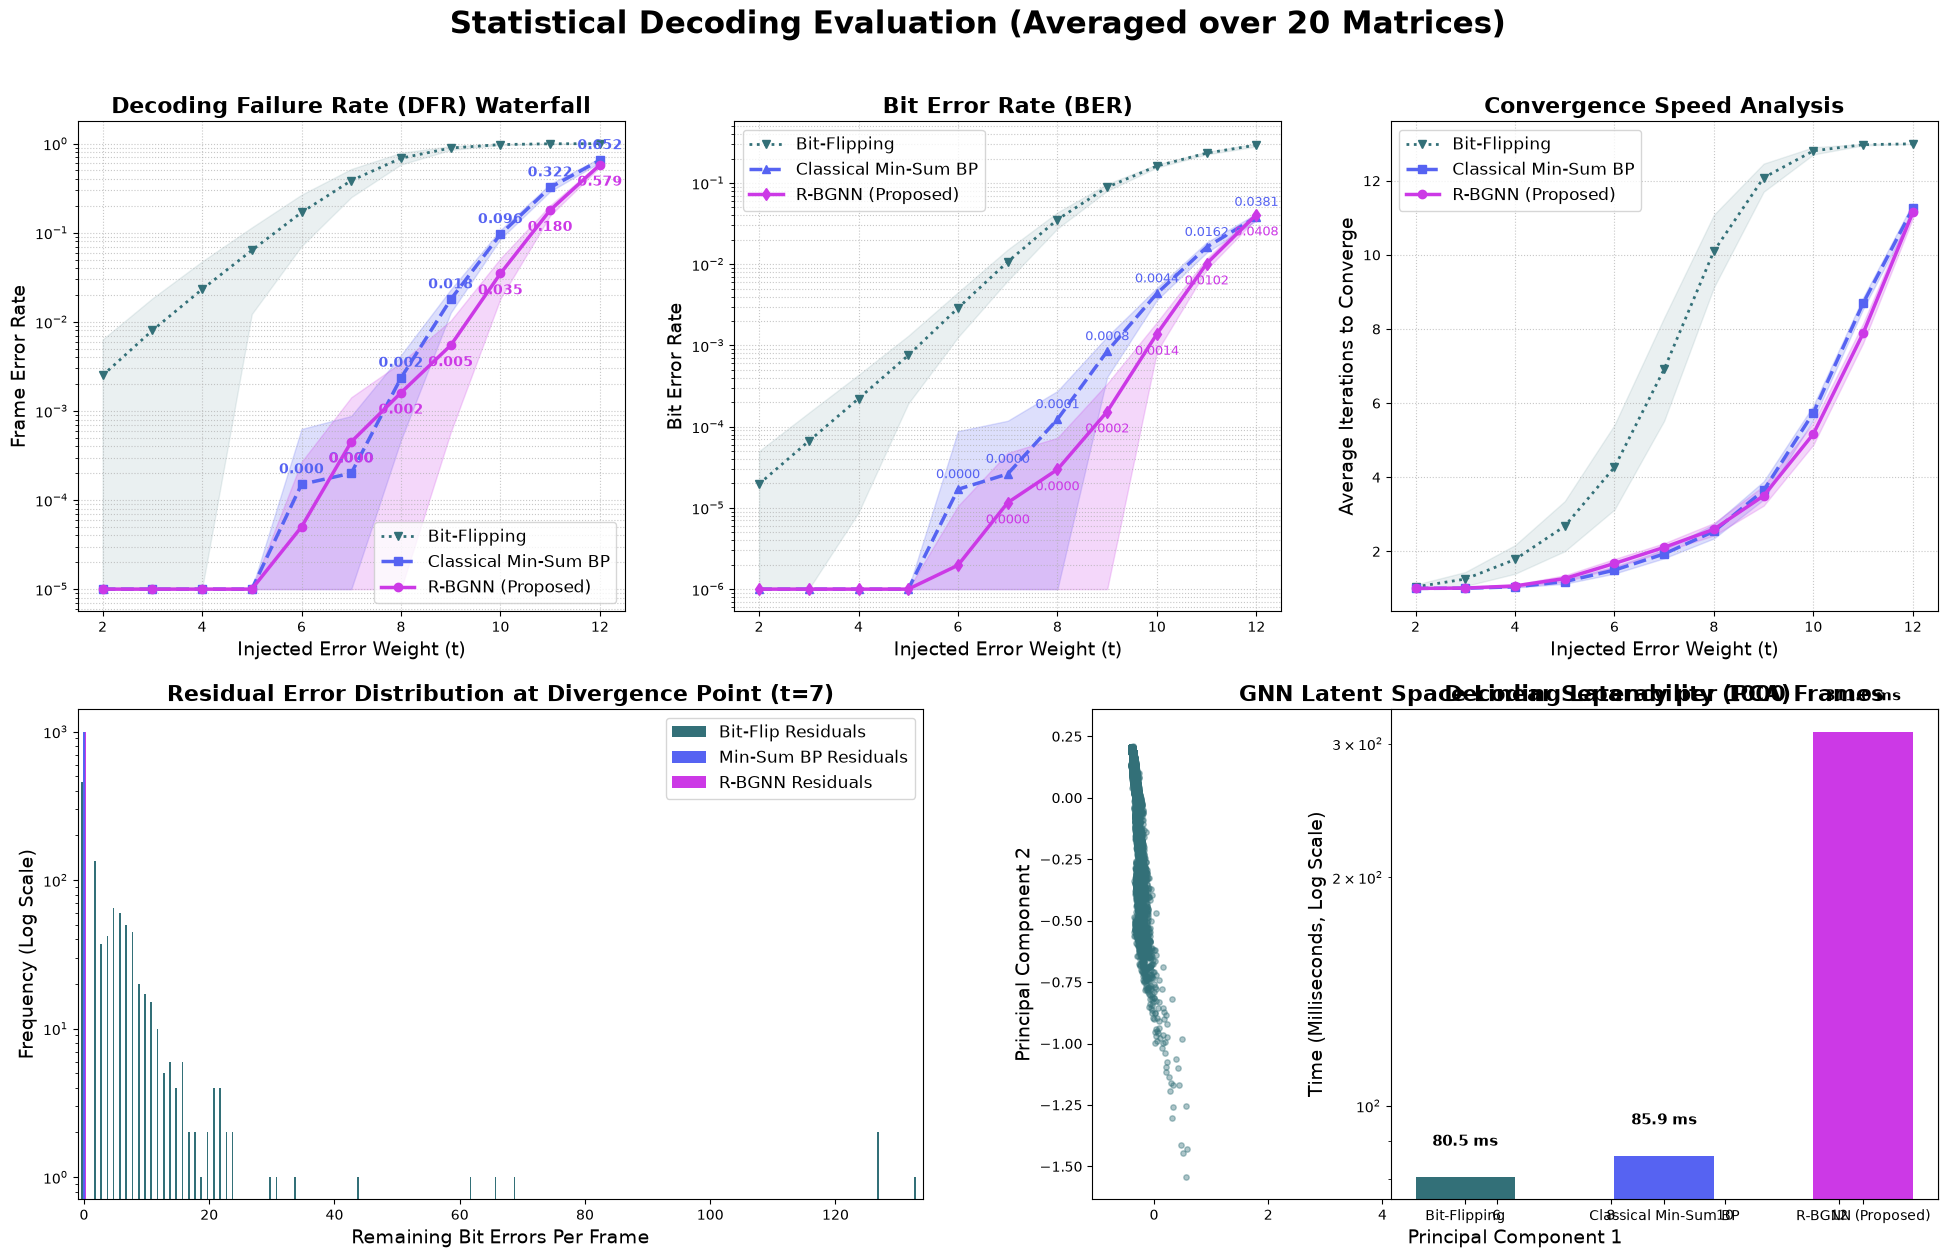

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. POINT THIS TO YOUR LATEST RUN FOLDER
# ==========================================
# Example: r"C:/Users/PT510/Downloads/project/sep1/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260911_120000"
RUN_DIR = r"C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637"
PHASE5_DIR = os.path.join(RUN_DIR, "Phase_5_Evaluation")

print("[1/2] Loading locked benchmark artifacts (No evaluation needed!)...")

# Load JSONs
with open(os.path.join(PHASE5_DIR, "final_evaluation_results.json"), "r") as f:
    eval_data = json.load(f)
with open(os.path.join(PHASE5_DIR, "latency_benchmark.json"), "r") as f:
    latency_data = json.load(f)

# Load NPZs
hist_data = np.load(os.path.join(PHASE5_DIR, "residual_error_histogram_data.npz"))
pca_data = np.load(os.path.join(PHASE5_DIR, "latent_pca_data.npz"))

# Extract Data
t_values = sorted([int(t) for t in eval_data["per_t"]])

def get_pooled_metric(data, algo, metric):
    return np.array([data["per_t"][str(t)][algo][metric] for t in t_values])

def get_iter_stats(data, algo):
    field = "exact_recovery_iterations" if algo == "RBGNN" else "syndrome_convergence_iterations"
    means, stds = [], []
    for t in t_values:
        graph_iters = [g["per_t"][str(t)][algo][field]["mean"] for g in data["graph_level"]]
        means.append(np.mean(graph_iters))
        stds.append(np.std(graph_iters))
    return np.array(means), np.array(stds)

# DFR & BER Arrays
ms_dfr_m, ms_dfr_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_dfr"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_dfr")
gnn_dfr_m, gnn_dfr_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_dfr"), get_pooled_metric(eval_data, "RBGNN", "std_graph_dfr")
bf_dfr_m, bf_dfr_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_dfr"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_dfr")

ms_ber_m, ms_ber_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_ber"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_ber")
gnn_ber_m, gnn_ber_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_ber"), get_pooled_metric(eval_data, "RBGNN", "std_graph_ber")
bf_ber_m, bf_ber_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_ber"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_ber")

# Iteration Arrays
ms_it_m, ms_it_s = get_iter_stats(eval_data, "SyndromeMinSumHeuristic")
gnn_it_m, gnn_it_s = get_iter_stats(eval_data, "RBGNN")
bf_it_m, bf_it_s = get_iter_stats(eval_data, "BitFlipping")

print("[2/2] Rendering Publication Dashboard...")

# ==========================================
# 2. PLOTTING CONFIGURATION
# ==========================================
C_MS = "#5663F2"      # Min-Sum (Soft Blue)
C_GNN = "#CC39E6"     # R-BGNN (Bright Magenta)
C_BF = "#337078"      # Bit-Flipping (Orange)
# C_BF = "#F39C12"      # Bit-Flipping (Orange)
C_SAFE = "#337078"    # Safe Bits (Deep Teal)

fig = plt.figure(figsize=(24, 14), facecolor='white')
fig.suptitle(f"Statistical Decoding Evaluation (Averaged over {eval_data['metadata']['test_graphs']} Matrices)", 
             fontsize=22, weight='bold', y=0.96)

# ---------------------------------------------------------
# SUBPLOT 1: DFR Waterfall
# ---------------------------------------------------------
ax1 = fig.add_subplot(231)
ax1.plot(t_values, np.clip(bf_dfr_m, 1e-5, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax1.fill_between(t_values, np.clip(bf_dfr_m - bf_dfr_s, 1e-5, 1.0), np.clip(bf_dfr_m + bf_dfr_s, 1e-5, 1.0), color=C_BF, alpha=0.1)

ax1.plot(t_values, np.clip(ms_dfr_m, 1e-5, 1.0), marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax1.fill_between(t_values, np.clip(ms_dfr_m - ms_dfr_s, 1e-5, 1.0), np.clip(ms_dfr_m + ms_dfr_s, 1e-5, 1.0), color=C_MS, alpha=0.2)

ax1.plot(t_values, np.clip(gnn_dfr_m, 1e-5, 1.0), marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax1.fill_between(t_values, np.clip(gnn_dfr_m - gnn_dfr_s, 1e-5, 1.0), np.clip(gnn_dfr_m + gnn_dfr_s, 1e-5, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if ms_dfr_m[i] > 1e-4:
        ax1.annotate(f"{ms_dfr_m[i]:.3f}", (t, ms_dfr_m[i]), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=10, weight='bold')
    if gnn_dfr_m[i] > 1e-4:
        ax1.annotate(f"{gnn_dfr_m[i]:.3f}", (t, gnn_dfr_m[i]), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=10, weight='bold')

ax1.set_yscale('log')
ax1.set_title("Decoding Failure Rate (DFR) Waterfall", fontsize=16, weight='bold')
ax1.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax1.set_ylabel("Frame Error Rate", fontsize=14)
ax1.grid(True, which="both", ls=":", alpha=0.7)
ax1.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 2: BER Curve
# ---------------------------------------------------------
ax2 = fig.add_subplot(232)
ax2.plot(t_values, np.clip(bf_ber_m, 1e-6, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax2.fill_between(t_values, np.clip(bf_ber_m - bf_ber_s, 1e-6, 1.0), np.clip(bf_ber_m + bf_ber_s, 1e-6, 1.0), color=C_BF, alpha=0.1)

ax2.plot(t_values, np.clip(ms_ber_m, 1e-6, 1.0), marker='^', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax2.fill_between(t_values, np.clip(ms_ber_m - ms_ber_s, 1e-6, 1.0), np.clip(ms_ber_m + ms_ber_s, 1e-6, 1.0), color=C_MS, alpha=0.2)

ax2.plot(t_values, np.clip(gnn_ber_m, 1e-6, 1.0), marker='d', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax2.fill_between(t_values, np.clip(gnn_ber_m - gnn_ber_s, 1e-6, 1.0), np.clip(gnn_ber_m + gnn_ber_s, 1e-6, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if ms_ber_m[i] > 1e-5:
        ax2.annotate(f"{ms_ber_m[i]:.4f}", (t, ms_ber_m[i]), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=9)
    if gnn_ber_m[i] > 1e-5:
        ax2.annotate(f"{gnn_ber_m[i]:.4f}", (t, gnn_ber_m[i]), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=9)

ax2.set_yscale('log')
ax2.set_title("Bit Error Rate (BER)", fontsize=16, weight='bold')
ax2.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax2.set_ylabel("Bit Error Rate", fontsize=14)
ax2.grid(True, which="both", ls=":", alpha=0.7)
ax2.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 3: Convergence Speed
# ---------------------------------------------------------
ax3 = fig.add_subplot(233)
ax3.plot(t_values, bf_it_m, marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax3.fill_between(t_values, np.clip(bf_it_m - bf_it_s, 0, None), bf_it_m + bf_it_s, color=C_BF, alpha=0.1)

ax3.plot(t_values, ms_it_m, marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax3.fill_between(t_values, np.clip(ms_it_m - ms_it_s, 0, None), ms_it_m + ms_it_s, color=C_MS, alpha=0.2)

ax3.plot(t_values, gnn_it_m, marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax3.fill_between(t_values, np.clip(gnn_it_m - gnn_it_s, 0, None), gnn_it_m + gnn_it_s, color=C_GNN, alpha=0.2)

ax3.set_title("Convergence Speed Analysis", fontsize=16, weight='bold')
ax3.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax3.set_ylabel("Average Iterations to Converge", fontsize=14)
ax3.grid(True, ls=":", alpha=0.7)
ax3.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 4: Residual Error Histogram (LOG SCALED, GROUPED)
# ---------------------------------------------------------
ax4 = fig.add_subplot(223)
target_t = int(hist_data['t'].item())

bf_errs = hist_data['bitflip']
ms_errs = hist_data['minsum']
gnn_errs = hist_data['gnn']

max_err = max(bf_errs.max(), ms_errs.max(), gnn_errs.max())
bins = np.arange(-0.5, max_err + 1.5, 1)

# Log=True prevents the 0-error bins from hiding the trapped frames
ax4.hist([bf_errs, ms_errs, gnn_errs], bins=bins, color=[C_BF, C_MS, C_GNN], 
         label=['Bit-Flip Residuals', 'Min-Sum BP Residuals', 'R-BGNN Residuals'], log=True)

ax4.set_title(f"Residual Error Distribution at Divergence Point (t={target_t})", fontsize=16, weight='bold')
ax4.set_xlabel("Remaining Bit Errors Per Frame", fontsize=14)
ax4.set_ylabel("Frequency (Log Scale)", fontsize=14)
ax4.set_xlim(-1, max(10, max_err + 1)) 
ax4.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 5: PCA Latent Space
# ---------------------------------------------------------
ax5 = fig.add_subplot(224)
pca_emb = pca_data['embeddings']
pca_labels = pca_data['labels']

safe = pca_labels == 0
err = pca_labels == 1

ax5.scatter(pca_emb[safe, 0], pca_emb[safe, 1], alpha=0.4, s=15, color=C_SAFE, label='Safe Bits (0)')
ax5.scatter(pca_emb[err, 0], pca_emb[err, 1], alpha=0.8, s=30, color=C_GNN, marker='x', label='Error Bits (1)')

ax5.set_title("GNN Latent Space Linear Separability (PCA)", fontsize=16, weight='bold')
ax5.set_xlabel("Principal Component 1", fontsize=14)
ax5.set_ylabel("Principal Component 2", fontsize=14)
ax5.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 6: Decoding Latency (Optional Addition)
# ---------------------------------------------------------
ax6 = fig.add_subplot(236)
lat_labels = ['Bit-Flipping', 'Classical Min-Sum BP', 'R-BGNN (Proposed)']
lat_times = [
    latency_data['BitFlipping']['median_ms'],
    latency_data['SyndromeMinSumHeuristic']['median_ms'],
    latency_data['RBGNN']['median_ms']
]
bars = ax6.bar(lat_labels, lat_times, color=[C_BF, C_MS, C_GNN], width=0.5)

ax6.set_yscale('log')
ax6.set_title("Decoding Latency per 1000 Frames", fontsize=16, weight='bold')
ax6.set_ylabel("Time (Milliseconds, Log Scale)", fontsize=14)

for bar in bars:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.1, 
             f'{bar.get_height():.1f} ms', ha='center', weight='bold', fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(PHASE5_DIR, "Master_Statistical_Dashboard.png")
plt.savefig(save_path, dpi=300)
print(f"[SUCCESS] Plot successfully saved to: {save_path}")
plt.show()

[1/2] Loading locked benchmark artifacts (No evaluation needed!)...
[2/2] Rendering Publication Dashboard...
[SUCCESS] Plot successfully saved to: C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637\Phase_5_Evaluation\Master_Statistical_Dashboard_CLEAN.png


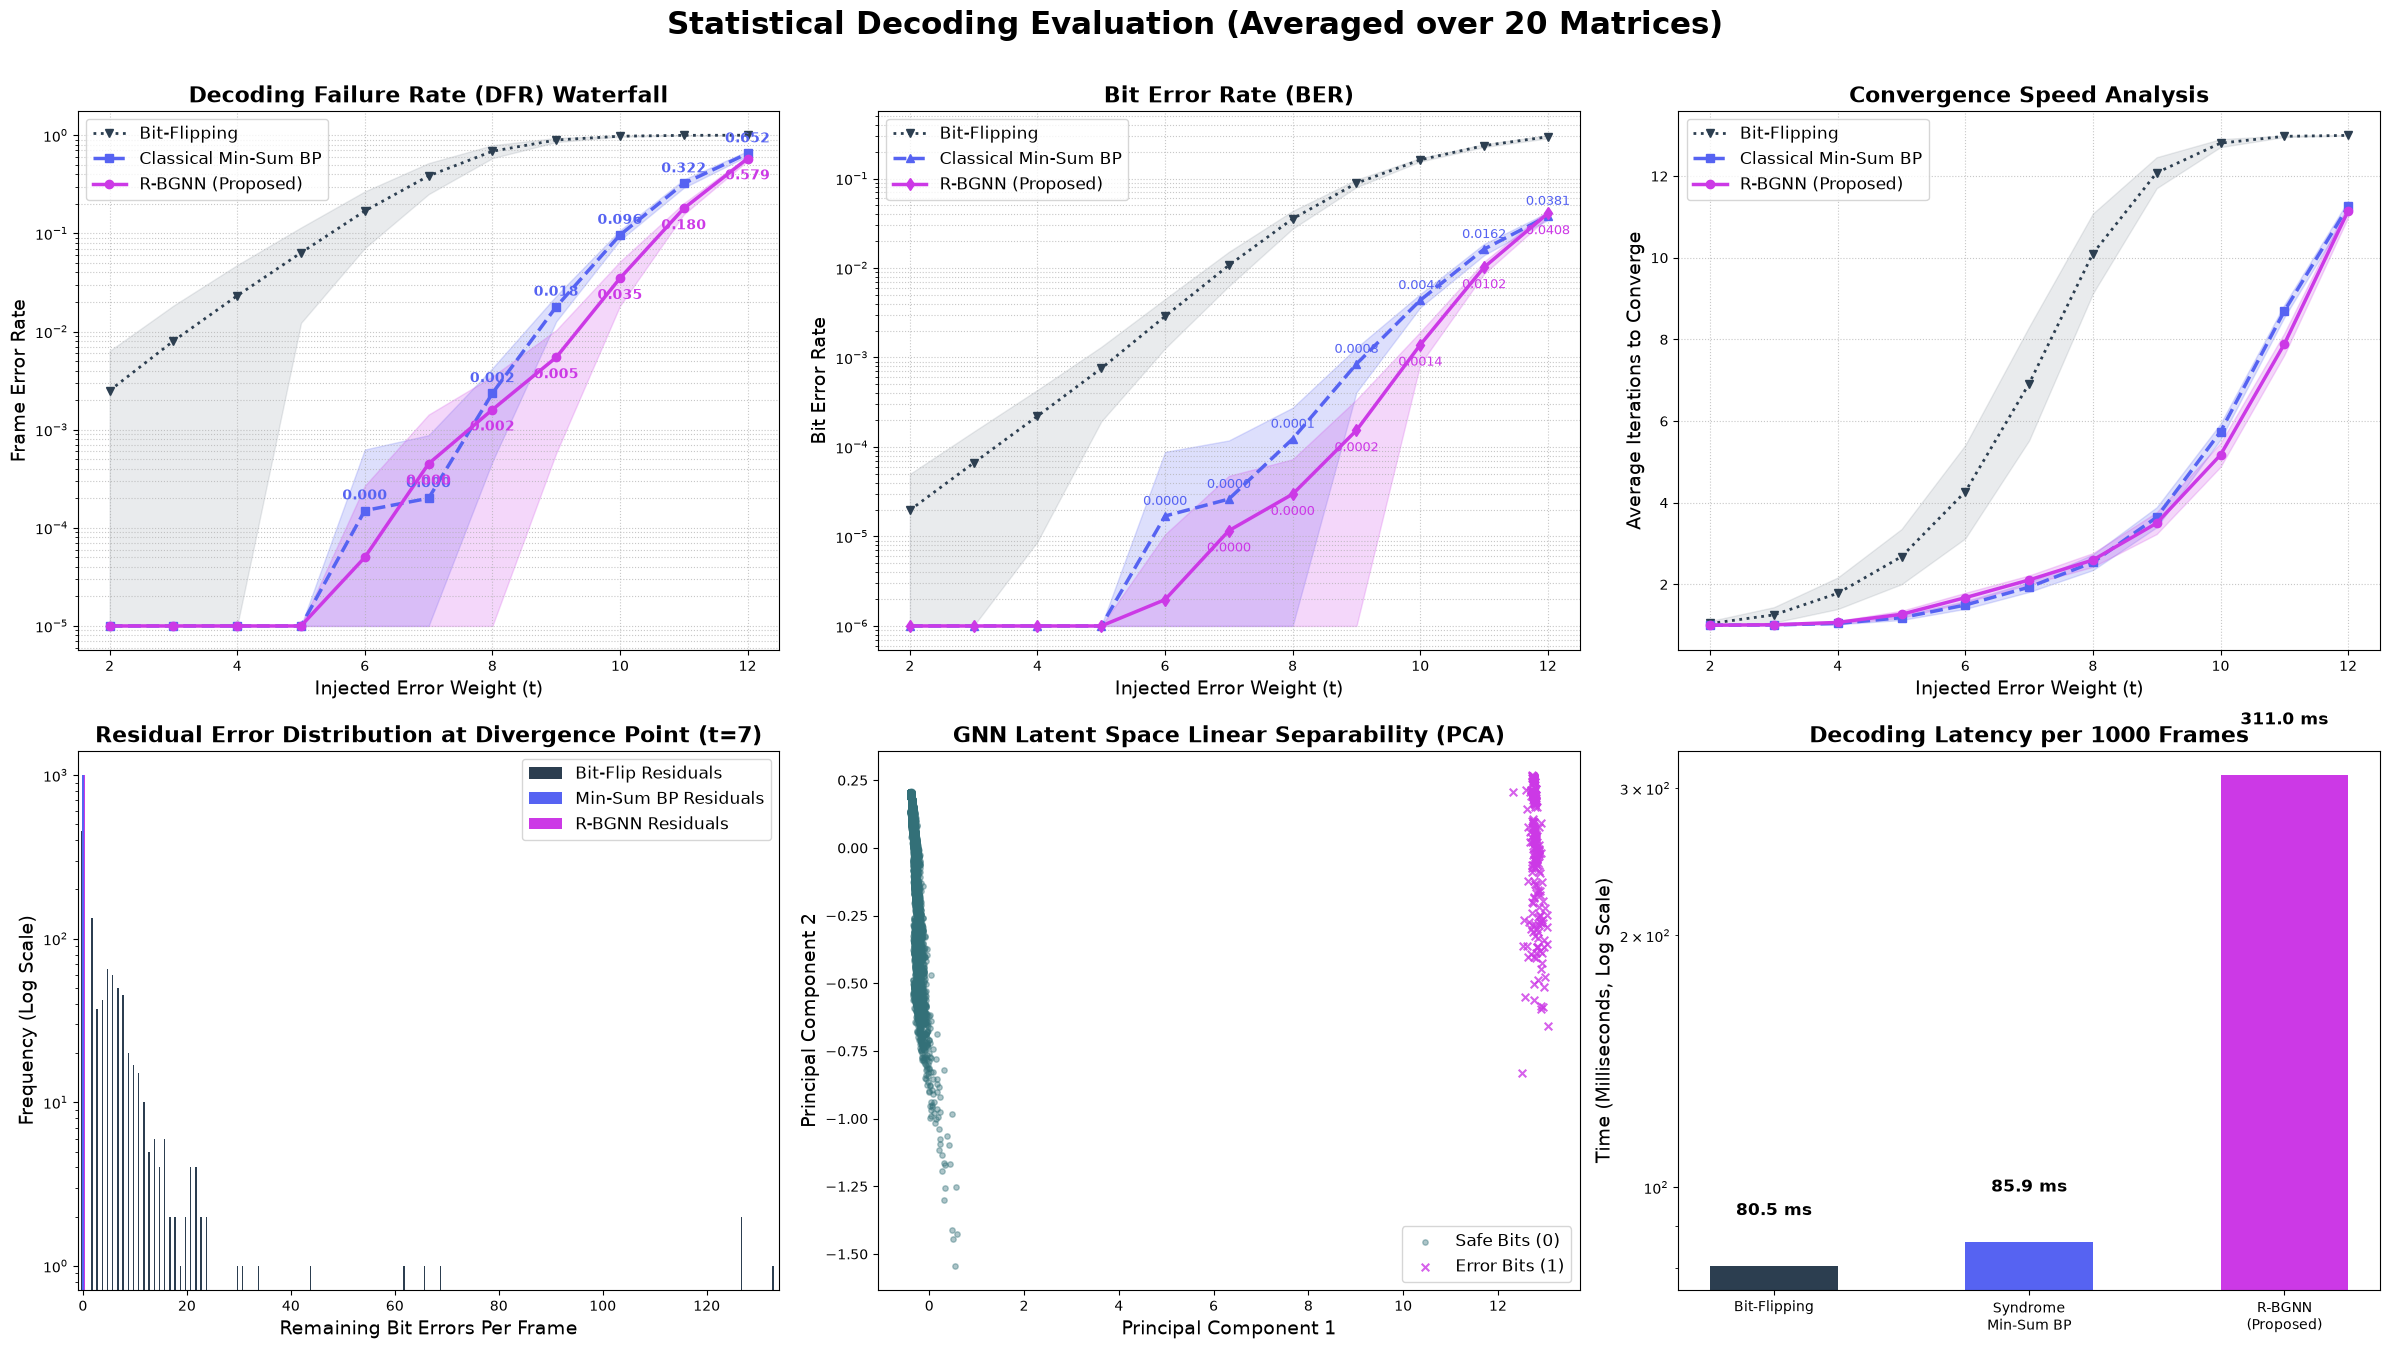

In [2]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. POINT THIS TO YOUR EXACT FOLDER
# ==========================================
RUN_DIR = r"C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637"
PHASE5_DIR = os.path.join(RUN_DIR, "Phase_5_Evaluation")

print("[1/2] Loading locked benchmark artifacts (No evaluation needed!)...")

# Load JSONs
with open(os.path.join(PHASE5_DIR, "final_evaluation_results.json"), "r") as f:
    eval_data = json.load(f)
with open(os.path.join(PHASE5_DIR, "latency_benchmark.json"), "r") as f:
    latency_data = json.load(f)

# Load NPZs
hist_data = np.load(os.path.join(PHASE5_DIR, "residual_error_histogram_data.npz"))
pca_data = np.load(os.path.join(PHASE5_DIR, "latent_pca_data.npz"))

# Extract Data
t_values = sorted([int(t) for t in eval_data["per_t"]])

def get_pooled_metric(data, algo, metric):
    return np.array([data["per_t"][str(t)][algo][metric] for t in t_values])

def get_iter_stats(data, algo):
    field = "exact_recovery_iterations" if algo == "RBGNN" else "syndrome_convergence_iterations"
    means, stds = [], []
    for t in t_values:
        graph_iters = [g["per_t"][str(t)][algo][field]["mean"] for g in data["graph_level"]]
        means.append(np.mean(graph_iters))
        stds.append(np.std(graph_iters))
    return np.array(means), np.array(stds)

# DFR & BER Arrays
ms_dfr_m, ms_dfr_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_dfr"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_dfr")
gnn_dfr_m, gnn_dfr_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_dfr"), get_pooled_metric(eval_data, "RBGNN", "std_graph_dfr")
bf_dfr_m, bf_dfr_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_dfr"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_dfr")

ms_ber_m, ms_ber_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_ber"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_ber")
gnn_ber_m, gnn_ber_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_ber"), get_pooled_metric(eval_data, "RBGNN", "std_graph_ber")
bf_ber_m, bf_ber_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_ber"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_ber")

# Iteration Arrays
ms_it_m, ms_it_s = get_iter_stats(eval_data, "SyndromeMinSumHeuristic")
gnn_it_m, gnn_it_s = get_iter_stats(eval_data, "RBGNN")
bf_it_m, bf_it_s = get_iter_stats(eval_data, "BitFlipping")

print("[2/2] Rendering Publication Dashboard...")

# ==========================================
# 2. PLOTTING CONFIGURATION
# ==========================================
C_MS = "#5663F2"      # Min-Sum (Soft Blue)
C_GNN = "#CC39E6"     # R-BGNN (Bright Magenta)
C_BF = "#2C3E50"      # Bit-Flipping (Dark Slate)
C_SAFE = "#337078"    # Safe Bits (Deep Teal)

# Clear any lingering messy plots from memory
plt.close('all')

fig = plt.figure(figsize=(24, 14), facecolor='white')
fig.suptitle(f"Statistical Decoding Evaluation (Averaged over {eval_data['metadata']['test_graphs']} Matrices)", 
             fontsize=22, weight='bold', y=0.96)

# ---------------------------------------------------------
# SUBPLOT 1: DFR Waterfall
# ---------------------------------------------------------
ax1 = fig.add_subplot(2, 3, 1) # <--- Fixed Grid Alignment
ax1.plot(t_values, np.clip(bf_dfr_m, 1e-5, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax1.fill_between(t_values, np.clip(bf_dfr_m - bf_dfr_s, 1e-5, 1.0), np.clip(bf_dfr_m + bf_dfr_s, 1e-5, 1.0), color=C_BF, alpha=0.1)

ax1.plot(t_values, np.clip(ms_dfr_m, 1e-5, 1.0), marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax1.fill_between(t_values, np.clip(ms_dfr_m - ms_dfr_s, 1e-5, 1.0), np.clip(ms_dfr_m + ms_dfr_s, 1e-5, 1.0), color=C_MS, alpha=0.2)

ax1.plot(t_values, np.clip(gnn_dfr_m, 1e-5, 1.0), marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax1.fill_between(t_values, np.clip(gnn_dfr_m - gnn_dfr_s, 1e-5, 1.0), np.clip(gnn_dfr_m + gnn_dfr_s, 1e-5, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if ms_dfr_m[i] > 1e-4:
        ax1.annotate(f"{ms_dfr_m[i]:.3f}", (t, ms_dfr_m[i]), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=10, weight='bold')
    if gnn_dfr_m[i] > 1e-4:
        ax1.annotate(f"{gnn_dfr_m[i]:.3f}", (t, gnn_dfr_m[i]), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=10, weight='bold')

ax1.set_yscale('log')
ax1.set_title("Decoding Failure Rate (DFR) Waterfall", fontsize=16, weight='bold')
ax1.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax1.set_ylabel("Frame Error Rate", fontsize=14)
ax1.grid(True, which="both", ls=":", alpha=0.7)
ax1.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 2: BER Curve
# ---------------------------------------------------------
ax2 = fig.add_subplot(2, 3, 2) # <--- Fixed Grid Alignment
ax2.plot(t_values, np.clip(bf_ber_m, 1e-6, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax2.fill_between(t_values, np.clip(bf_ber_m - bf_ber_s, 1e-6, 1.0), np.clip(bf_ber_m + bf_ber_s, 1e-6, 1.0), color=C_BF, alpha=0.1)

ax2.plot(t_values, np.clip(ms_ber_m, 1e-6, 1.0), marker='^', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax2.fill_between(t_values, np.clip(ms_ber_m - ms_ber_s, 1e-6, 1.0), np.clip(ms_ber_m + ms_ber_s, 1e-6, 1.0), color=C_MS, alpha=0.2)

ax2.plot(t_values, np.clip(gnn_ber_m, 1e-6, 1.0), marker='d', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax2.fill_between(t_values, np.clip(gnn_ber_m - gnn_ber_s, 1e-6, 1.0), np.clip(gnn_ber_m + gnn_ber_s, 1e-6, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if ms_ber_m[i] > 1e-5:
        ax2.annotate(f"{ms_ber_m[i]:.4f}", (t, ms_ber_m[i]), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=9)
    if gnn_ber_m[i] > 1e-5:
        ax2.annotate(f"{gnn_ber_m[i]:.4f}", (t, gnn_ber_m[i]), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=9)

ax2.set_yscale('log')
ax2.set_title("Bit Error Rate (BER)", fontsize=16, weight='bold')
ax2.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax2.set_ylabel("Bit Error Rate", fontsize=14)
ax2.grid(True, which="both", ls=":", alpha=0.7)
ax2.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 3: Convergence Speed
# ---------------------------------------------------------
ax3 = fig.add_subplot(2, 3, 3) # <--- Fixed Grid Alignment
ax3.plot(t_values, bf_it_m, marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax3.fill_between(t_values, np.clip(bf_it_m - bf_it_s, 0, None), bf_it_m + bf_it_s, color=C_BF, alpha=0.1)

ax3.plot(t_values, ms_it_m, marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax3.fill_between(t_values, np.clip(ms_it_m - ms_it_s, 0, None), ms_it_m + ms_it_s, color=C_MS, alpha=0.2)

ax3.plot(t_values, gnn_it_m, marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax3.fill_between(t_values, np.clip(gnn_it_m - gnn_it_s, 0, None), gnn_it_m + gnn_it_s, color=C_GNN, alpha=0.2)

ax3.set_title("Convergence Speed Analysis", fontsize=16, weight='bold')
ax3.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax3.set_ylabel("Average Iterations to Converge", fontsize=14)
ax3.grid(True, ls=":", alpha=0.7)
ax3.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 4: Residual Error Histogram 
# ---------------------------------------------------------
ax4 = fig.add_subplot(2, 3, 4) # <--- Fixed Grid Alignment
target_t = int(hist_data['t'].item())

bf_errs = hist_data['bitflip']
ms_errs = hist_data['minsum']
gnn_errs = hist_data['gnn']

max_err = max(bf_errs.max(), ms_errs.max(), gnn_errs.max())
bins = np.arange(-0.5, max_err + 1.5, 1)

ax4.hist([bf_errs, ms_errs, gnn_errs], bins=bins, color=[C_BF, C_MS, C_GNN], 
         label=['Bit-Flip Residuals', 'Min-Sum BP Residuals', 'R-BGNN Residuals'], log=True)

ax4.set_title(f"Residual Error Distribution at Divergence Point (t={target_t})", fontsize=16, weight='bold')
ax4.set_xlabel("Remaining Bit Errors Per Frame", fontsize=14)
ax4.set_ylabel("Frequency (Log Scale)", fontsize=14)
ax4.set_xlim(-1, max(10, max_err + 1)) 
ax4.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 5: PCA Latent Space
# ---------------------------------------------------------
ax5 = fig.add_subplot(2, 3, 5) # <--- Fixed Grid Alignment
pca_emb = pca_data['embeddings']
pca_labels = pca_data['labels']

safe = pca_labels == 0
err = pca_labels == 1

ax5.scatter(pca_emb[safe, 0], pca_emb[safe, 1], alpha=0.4, s=15, color=C_SAFE, label='Safe Bits (0)')
ax5.scatter(pca_emb[err, 0], pca_emb[err, 1], alpha=0.8, s=30, color=C_GNN, marker='x', label='Error Bits (1)')

ax5.set_title("GNN Latent Space Linear Separability (PCA)", fontsize=16, weight='bold')
ax5.set_xlabel("Principal Component 1", fontsize=14)
ax5.set_ylabel("Principal Component 2", fontsize=14)
ax5.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 6: Decoding Latency
# ---------------------------------------------------------
ax6 = fig.add_subplot(2, 3, 6) # <--- Fixed Grid Alignment
lat_labels = ['Bit-Flipping', 'Syndrome\nMin-Sum BP', 'R-BGNN\n(Proposed)']
lat_times = [
    latency_data['BitFlipping']['median_ms'],
    latency_data['SyndromeMinSumHeuristic']['median_ms'],
    latency_data['RBGNN']['median_ms']
]
bars = ax6.bar(lat_labels, lat_times, color=[C_BF, C_MS, C_GNN], width=0.5)

ax6.set_yscale('log')
ax6.set_title("Decoding Latency per 1000 Frames", fontsize=16, weight='bold')
ax6.set_ylabel("Time (Milliseconds, Log Scale)", fontsize=14)

for bar in bars:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15, 
             f'{bar.get_height():.1f} ms', ha='center', weight='bold', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(PHASE5_DIR, "Master_Statistical_Dashboard_CLEAN.png")
plt.savefig(save_path, dpi=300)
print(f"[SUCCESS] Plot successfully saved to: {save_path}")
plt.show()

[1/2] Loading locked benchmark artifacts (No evaluation needed!)...
[2/2] Rendering Publication Dashboard...
[SUCCESS] Plot successfully saved to: C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637\Phase_5_Evaluation\Master_Statistical_Dashboard_CLEAN_SIGFIGS.png


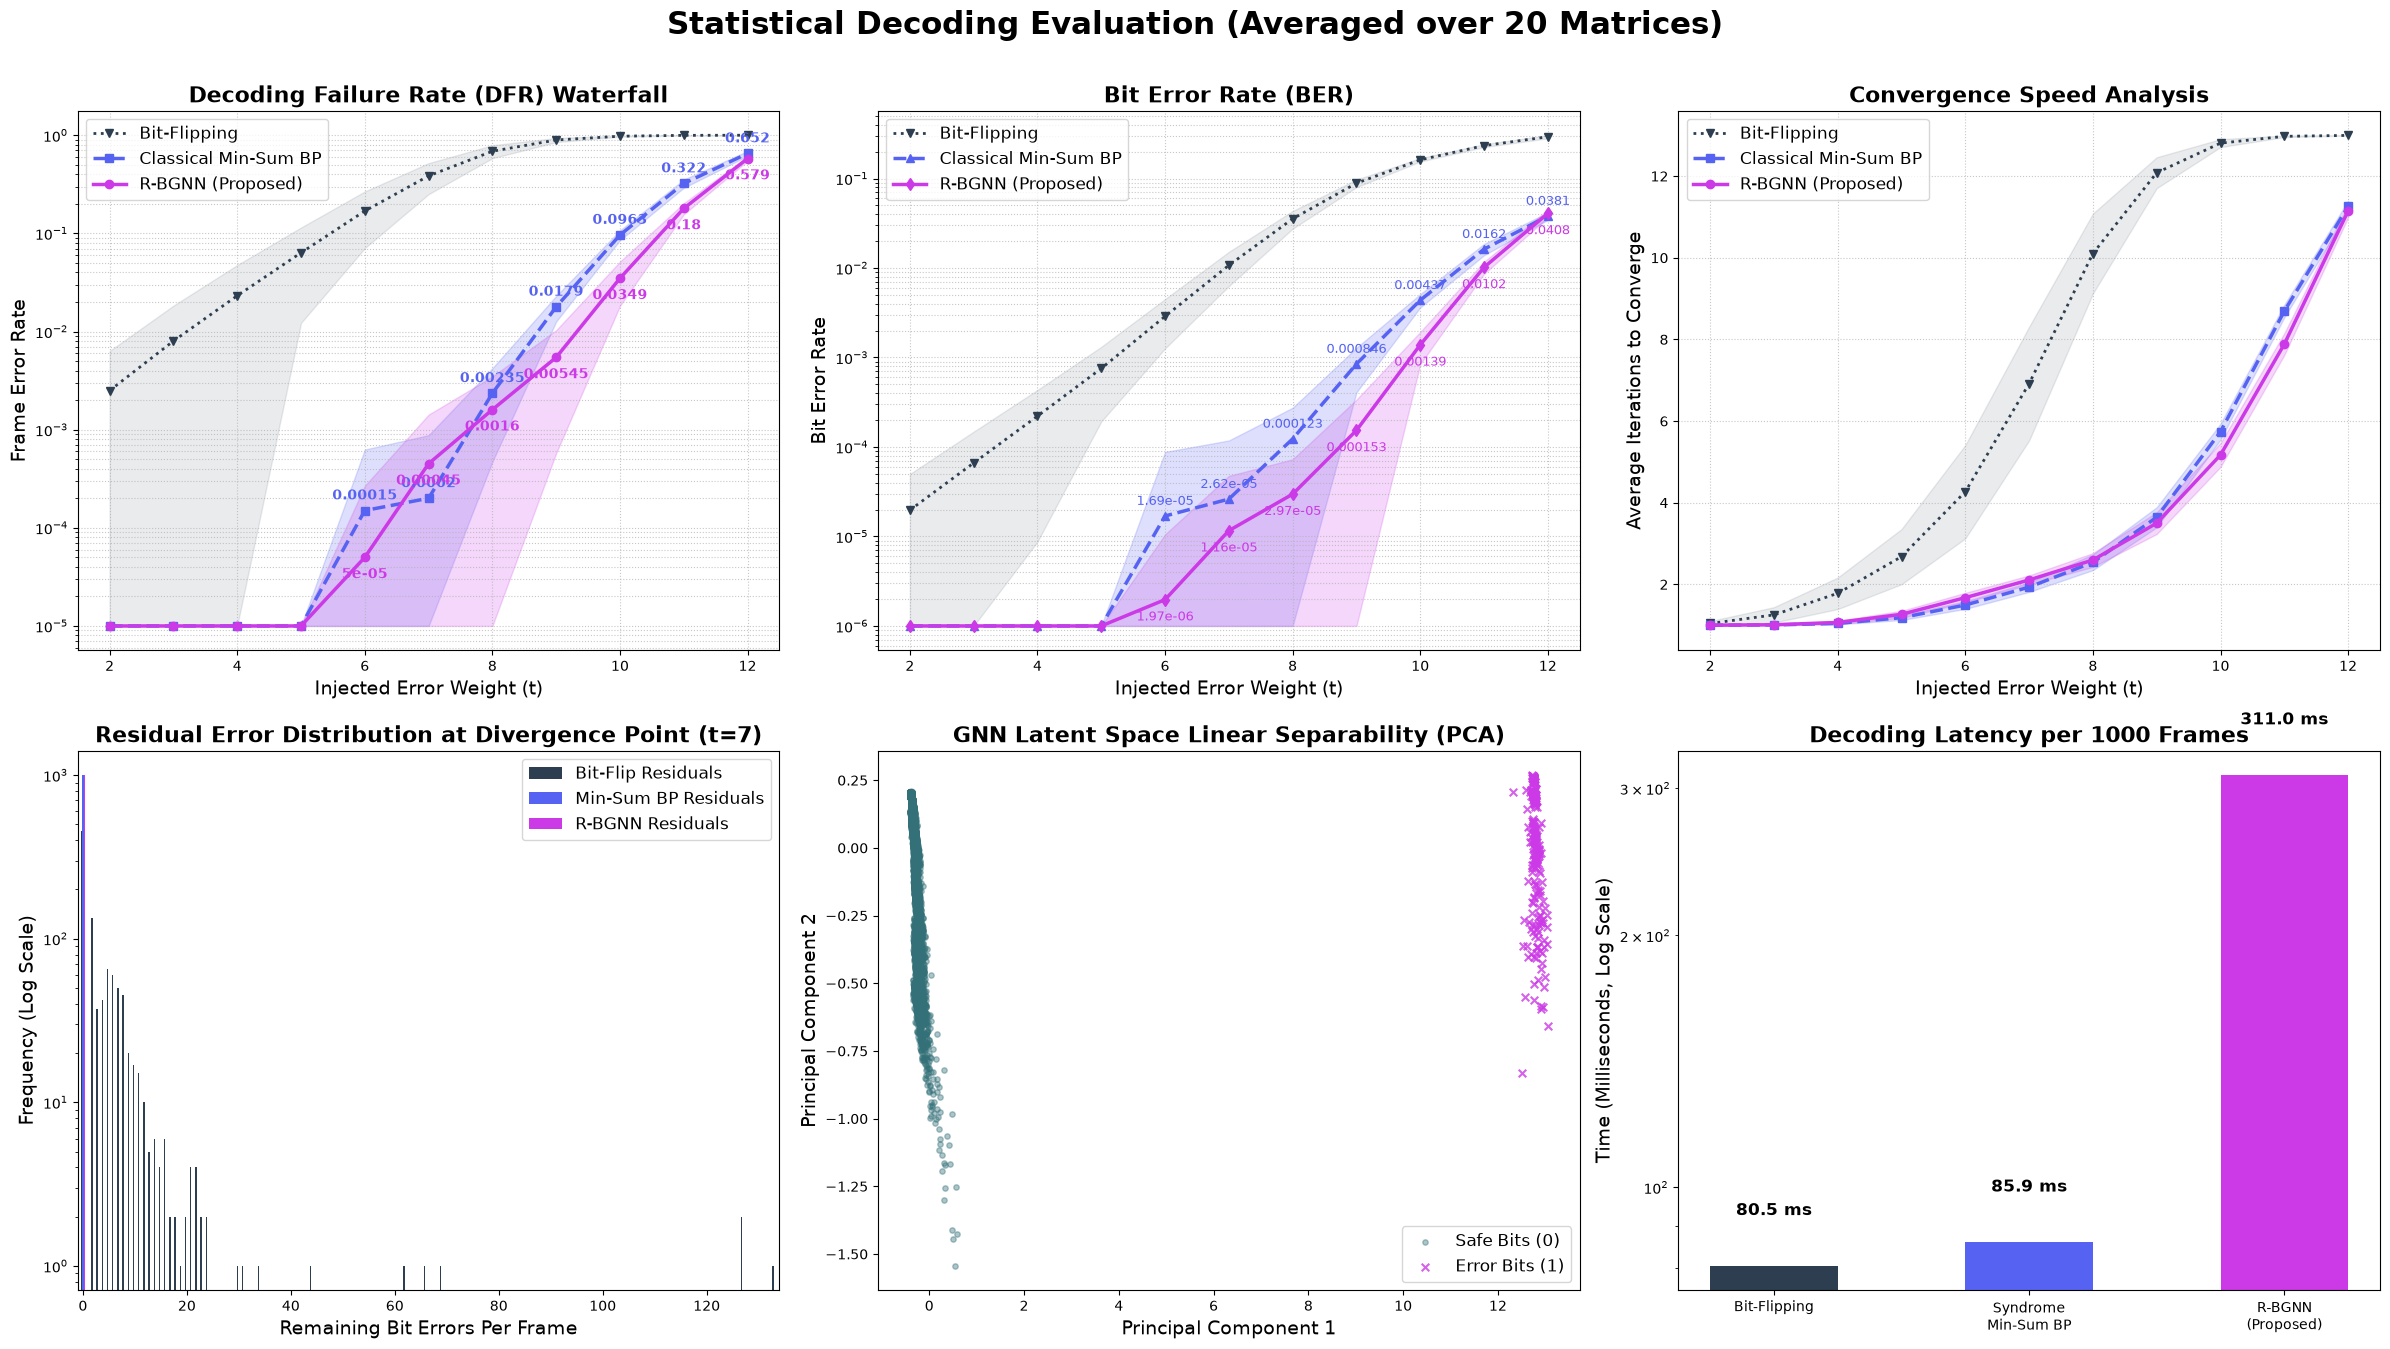

In [3]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. POINT THIS TO YOUR EXACT FOLDER
# ==========================================
RUN_DIR = r"C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260908_135637"
PHASE5_DIR = os.path.join(RUN_DIR, "Phase_5_Evaluation")

print("[1/2] Loading locked benchmark artifacts (No evaluation needed!)...")

# Load JSONs
with open(os.path.join(PHASE5_DIR, "final_evaluation_results.json"), "r") as f:
    eval_data = json.load(f)
with open(os.path.join(PHASE5_DIR, "latency_benchmark.json"), "r") as f:
    latency_data = json.load(f)

# Load NPZs
hist_data = np.load(os.path.join(PHASE5_DIR, "residual_error_histogram_data.npz"))
pca_data = np.load(os.path.join(PHASE5_DIR, "latent_pca_data.npz"))

# Extract Data
t_values = sorted([int(t) for t in eval_data["per_t"]])

def get_pooled_metric(data, algo, metric):
    return np.array([data["per_t"][str(t)][algo][metric] for t in t_values])

def get_iter_stats(data, algo):
    field = "exact_recovery_iterations" if algo == "RBGNN" else "syndrome_convergence_iterations"
    means, stds = [], []
    for t in t_values:
        graph_iters = [g["per_t"][str(t)][algo][field]["mean"] for g in data["graph_level"]]
        means.append(np.mean(graph_iters))
        stds.append(np.std(graph_iters))
    return np.array(means), np.array(stds)

# DFR & BER Arrays
ms_dfr_m, ms_dfr_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_dfr"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_dfr")
gnn_dfr_m, gnn_dfr_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_dfr"), get_pooled_metric(eval_data, "RBGNN", "std_graph_dfr")
bf_dfr_m, bf_dfr_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_dfr"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_dfr")

ms_ber_m, ms_ber_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_ber"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_ber")
gnn_ber_m, gnn_ber_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_ber"), get_pooled_metric(eval_data, "RBGNN", "std_graph_ber")
bf_ber_m, bf_ber_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_ber"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_ber")

# Iteration Arrays
ms_it_m, ms_it_s = get_iter_stats(eval_data, "SyndromeMinSumHeuristic")
gnn_it_m, gnn_it_s = get_iter_stats(eval_data, "RBGNN")
bf_it_m, bf_it_s = get_iter_stats(eval_data, "BitFlipping")

print("[2/2] Rendering Publication Dashboard...")

# ==========================================
# 2. PLOTTING CONFIGURATION
# ==========================================
C_MS = "#5663F2"      # Min-Sum (Soft Blue)
C_GNN = "#CC39E6"     # R-BGNN (Bright Magenta)
C_BF = "#2C3E50"      # Bit-Flipping (Dark Slate)
C_SAFE = "#337078"    # Safe Bits (Deep Teal)

# Clear any lingering messy plots from memory
plt.close('all')

fig = plt.figure(figsize=(24, 14), facecolor='white')
fig.suptitle(f"Statistical Decoding Evaluation (Averaged over {eval_data['metadata']['test_graphs']} Matrices)", 
             fontsize=22, weight='bold', y=0.96)

# Helper function for intelligent significant figure formatting
def fmt_sigfig(val):
    if val <= 1e-6:
        return ""
    # Use 3 significant digits. Switches to scientific (e.g., 1.23e-4) for very small numbers.
    return f"{val:.3g}"

# ---------------------------------------------------------
# SUBPLOT 1: DFR Waterfall
# ---------------------------------------------------------
ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(t_values, np.clip(bf_dfr_m, 1e-5, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax1.fill_between(t_values, np.clip(bf_dfr_m - bf_dfr_s, 1e-5, 1.0), np.clip(bf_dfr_m + bf_dfr_s, 1e-5, 1.0), color=C_BF, alpha=0.1)

ax1.plot(t_values, np.clip(ms_dfr_m, 1e-5, 1.0), marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax1.fill_between(t_values, np.clip(ms_dfr_m - ms_dfr_s, 1e-5, 1.0), np.clip(ms_dfr_m + ms_dfr_s, 1e-5, 1.0), color=C_MS, alpha=0.2)

ax1.plot(t_values, np.clip(gnn_dfr_m, 1e-5, 1.0), marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax1.fill_between(t_values, np.clip(gnn_dfr_m - gnn_dfr_s, 1e-5, 1.0), np.clip(gnn_dfr_m + gnn_dfr_s, 1e-5, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    val_ms = ms_dfr_m[i]
    val_gnn = gnn_dfr_m[i]
    if val_ms > 1e-5:
        ax1.annotate(fmt_sigfig(val_ms), (t, val_ms), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=10, weight='bold')
    if val_gnn > 1e-5:
        ax1.annotate(fmt_sigfig(val_gnn), (t, val_gnn), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=10, weight='bold')

ax1.set_yscale('log')
ax1.set_title("Decoding Failure Rate (DFR) Waterfall", fontsize=16, weight='bold')
ax1.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax1.set_ylabel("Frame Error Rate", fontsize=14)
ax1.grid(True, which="both", ls=":", alpha=0.7)
ax1.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 2: BER Curve
# ---------------------------------------------------------
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(t_values, np.clip(bf_ber_m, 1e-6, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax2.fill_between(t_values, np.clip(bf_ber_m - bf_ber_s, 1e-6, 1.0), np.clip(bf_ber_m + bf_ber_s, 1e-6, 1.0), color=C_BF, alpha=0.1)

ax2.plot(t_values, np.clip(ms_ber_m, 1e-6, 1.0), marker='^', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax2.fill_between(t_values, np.clip(ms_ber_m - ms_ber_s, 1e-6, 1.0), np.clip(ms_ber_m + ms_ber_s, 1e-6, 1.0), color=C_MS, alpha=0.2)

ax2.plot(t_values, np.clip(gnn_ber_m, 1e-6, 1.0), marker='d', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax2.fill_between(t_values, np.clip(gnn_ber_m - gnn_ber_s, 1e-6, 1.0), np.clip(gnn_ber_m + gnn_ber_s, 1e-6, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    val_ms = ms_ber_m[i]
    val_gnn = gnn_ber_m[i]
    if val_ms > 1e-6:
        ax2.annotate(fmt_sigfig(val_ms), (t, val_ms), textcoords="offset points", xytext=(0,8), ha='center', color=C_MS, fontsize=9)
    if val_gnn > 1e-6:
        ax2.annotate(fmt_sigfig(val_gnn), (t, val_gnn), textcoords="offset points", xytext=(0,-15), ha='center', color=C_GNN, fontsize=9)

ax2.set_yscale('log')
ax2.set_title("Bit Error Rate (BER)", fontsize=16, weight='bold')
ax2.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax2.set_ylabel("Bit Error Rate", fontsize=14)
ax2.grid(True, which="both", ls=":", alpha=0.7)
ax2.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 3: Convergence Speed
# ---------------------------------------------------------
ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(t_values, bf_it_m, marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax3.fill_between(t_values, np.clip(bf_it_m - bf_it_s, 0, None), bf_it_m + bf_it_s, color=C_BF, alpha=0.1)

ax3.plot(t_values, ms_it_m, marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax3.fill_between(t_values, np.clip(ms_it_m - ms_it_s, 0, None), ms_it_m + ms_it_s, color=C_MS, alpha=0.2)

ax3.plot(t_values, gnn_it_m, marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax3.fill_between(t_values, np.clip(gnn_it_m - gnn_it_s, 0, None), gnn_it_m + gnn_it_s, color=C_GNN, alpha=0.2)

ax3.set_title("Convergence Speed Analysis", fontsize=16, weight='bold')
ax3.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax3.set_ylabel("Average Iterations to Converge", fontsize=14)
ax3.grid(True, ls=":", alpha=0.7)
ax3.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 4: Residual Error Histogram 
# ---------------------------------------------------------
ax4 = fig.add_subplot(2, 3, 4)
target_t = int(hist_data['t'].item())

bf_errs = hist_data['bitflip']
ms_errs = hist_data['minsum']
gnn_errs = hist_data['gnn']

max_err = max(bf_errs.max(), ms_errs.max(), gnn_errs.max())
bins = np.arange(-0.5, max_err + 1.5, 1)

ax4.hist([bf_errs, ms_errs, gnn_errs], bins=bins, color=[C_BF, C_MS, C_GNN], 
         label=['Bit-Flip Residuals', 'Min-Sum BP Residuals', 'R-BGNN Residuals'], log=True)

ax4.set_title(f"Residual Error Distribution at Divergence Point (t={target_t})", fontsize=16, weight='bold')
ax4.set_xlabel("Remaining Bit Errors Per Frame", fontsize=14)
ax4.set_ylabel("Frequency (Log Scale)", fontsize=14)
ax4.set_xlim(-1, max(10, max_err + 1)) 
ax4.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 5: PCA Latent Space
# ---------------------------------------------------------
ax5 = fig.add_subplot(2, 3, 5)
pca_emb = pca_data['embeddings']
pca_labels = pca_data['labels']

safe = pca_labels == 0
err = pca_labels == 1

ax5.scatter(pca_emb[safe, 0], pca_emb[safe, 1], alpha=0.4, s=15, color=C_SAFE, label='Safe Bits (0)')
ax5.scatter(pca_emb[err, 0], pca_emb[err, 1], alpha=0.8, s=30, color=C_GNN, marker='x', label='Error Bits (1)')

ax5.set_title("GNN Latent Space Linear Separability (PCA)", fontsize=16, weight='bold')
ax5.set_xlabel("Principal Component 1", fontsize=14)
ax5.set_ylabel("Principal Component 2", fontsize=14)
ax5.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 6: Decoding Latency
# ---------------------------------------------------------
ax6 = fig.add_subplot(2, 3, 6)
lat_labels = ['Bit-Flipping', 'Syndrome\nMin-Sum BP', 'R-BGNN\n(Proposed)']
lat_times = [
    latency_data['BitFlipping']['median_ms'],
    latency_data['SyndromeMinSumHeuristic']['median_ms'],
    latency_data['RBGNN']['median_ms']
]
bars = ax6.bar(lat_labels, lat_times, color=[C_BF, C_MS, C_GNN], width=0.5)

ax6.set_yscale('log')
ax6.set_title("Decoding Latency per 1000 Frames", fontsize=16, weight='bold')
ax6.set_ylabel("Time (Milliseconds, Log Scale)", fontsize=14)

for bar in bars:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15, 
             f'{bar.get_height():.1f} ms', ha='center', weight='bold', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(PHASE5_DIR, "Master_Statistical_Dashboard_CLEAN_SIGFIGS.png")
plt.savefig(save_path, dpi=300)
print(f"[SUCCESS] Plot successfully saved to: {save_path}")
plt.show()

[1/2] Loading locked benchmark artifacts (No evaluation needed!)...
[2/2] Rendering Publication Dashboard...
[SUCCESS] Plot successfully saved to: C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260912_094545\Phase_5_Evaluation\Master_Statistical_Dashboard_FULLY_ANNOTATED.png


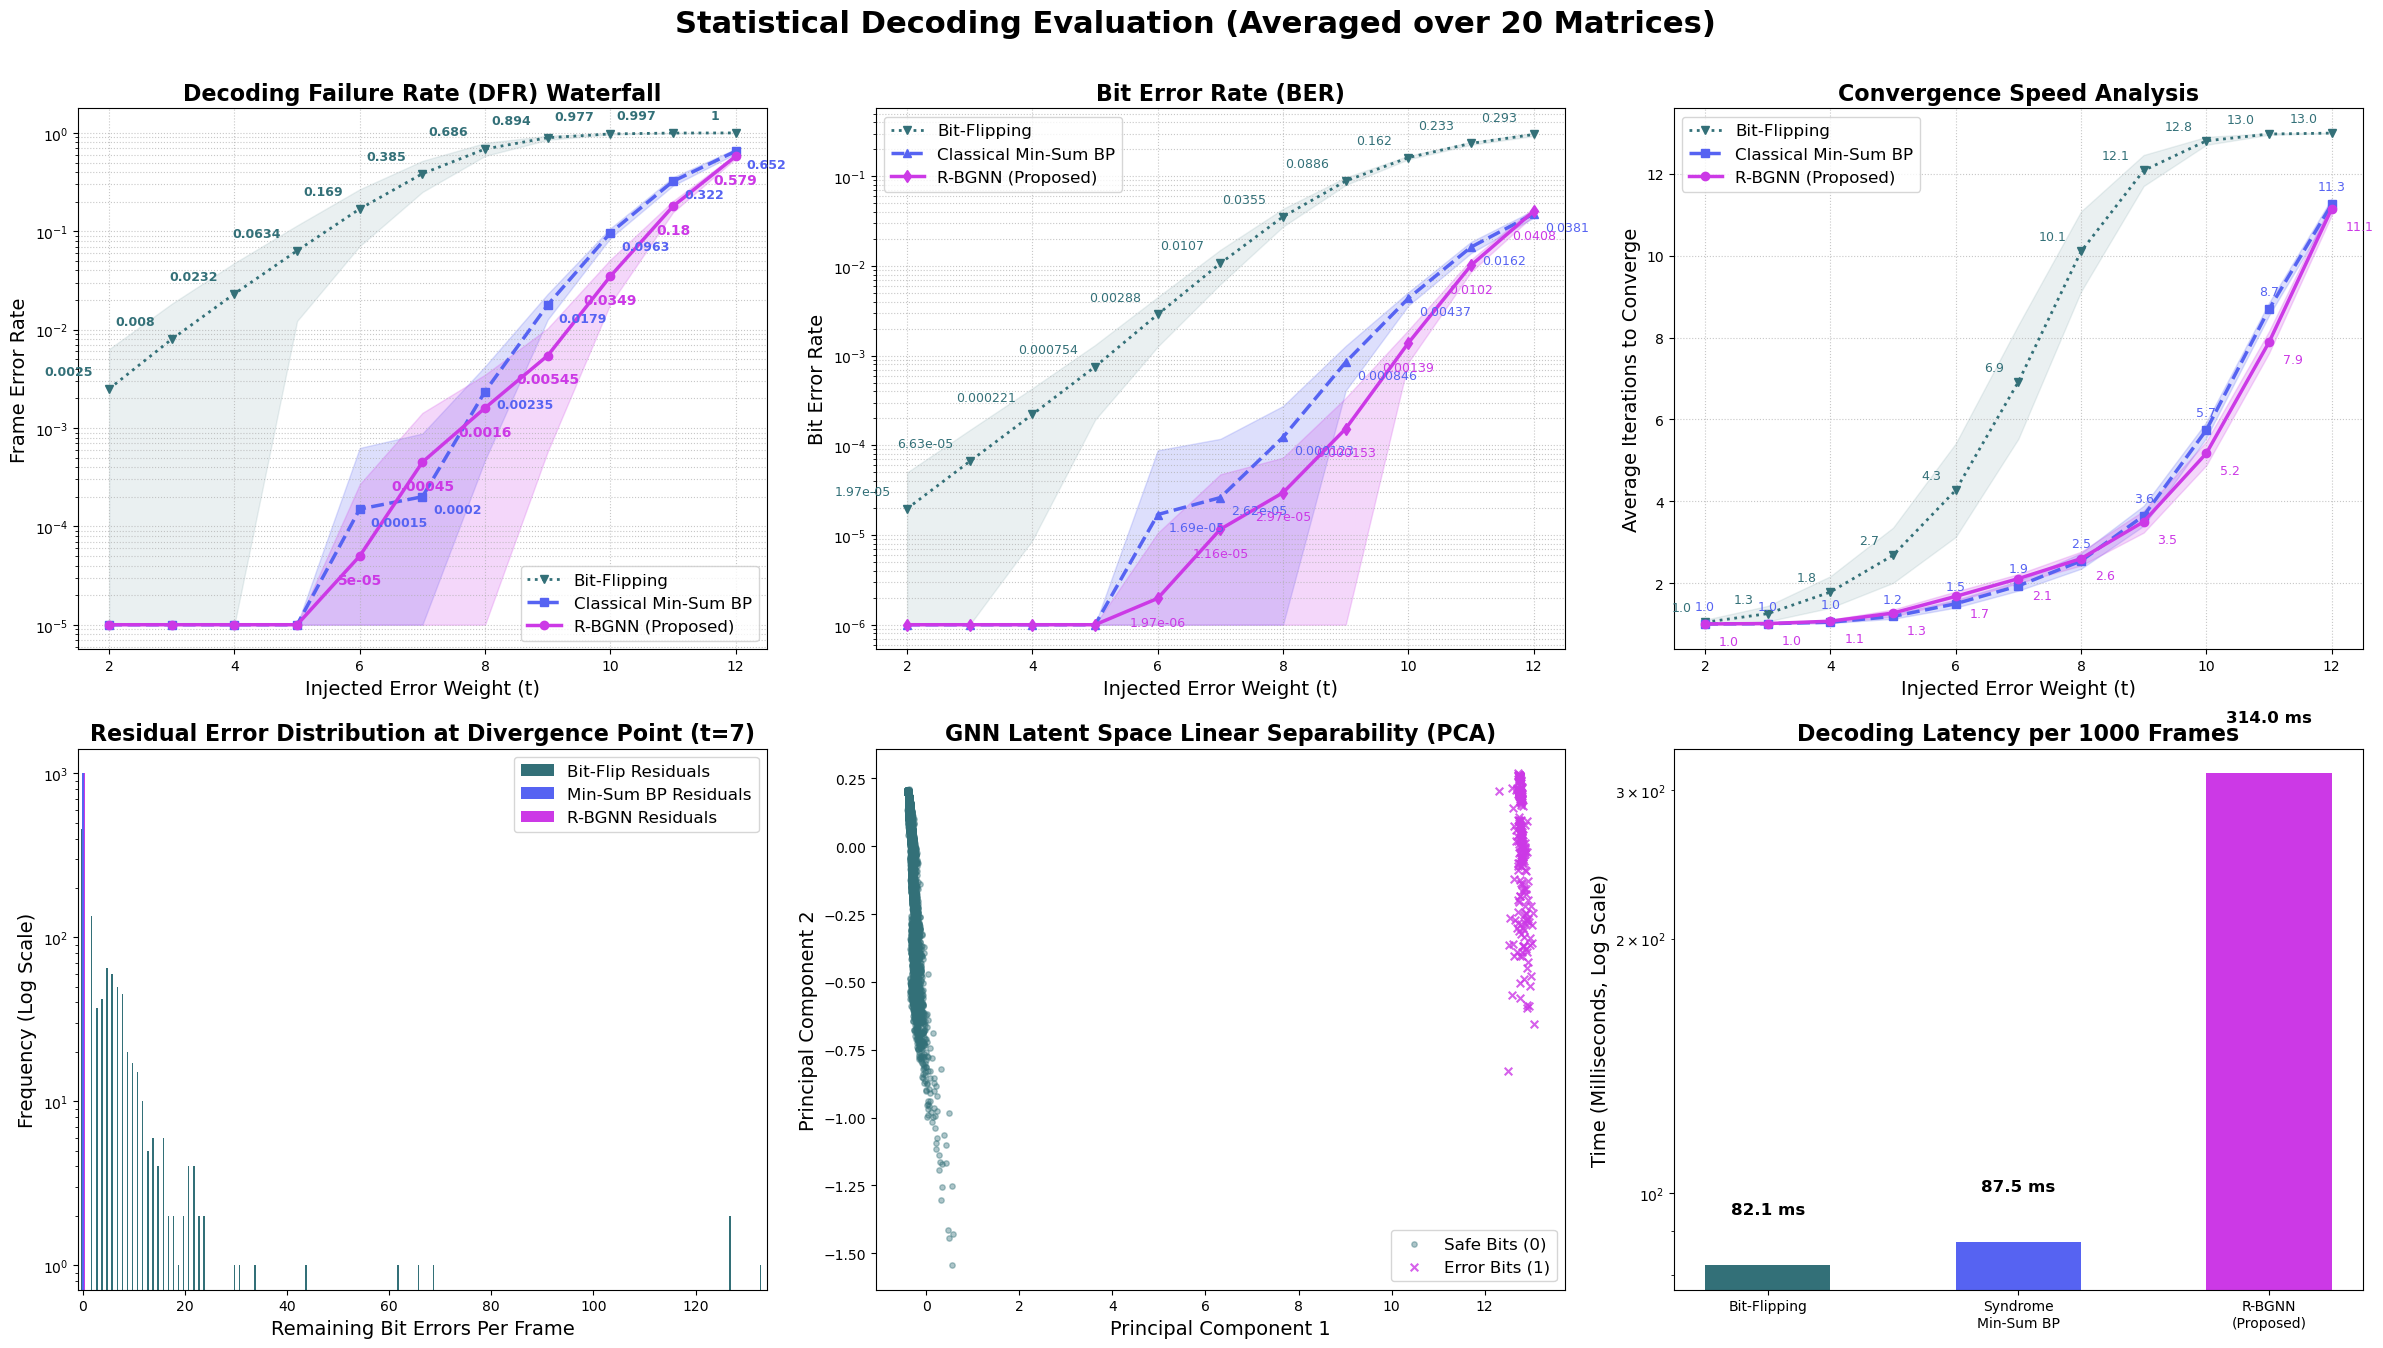

In [3]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. POINT THIS TO YOUR EXACT FOLDER
# ==========================================
RUN_DIR = r"C:/Users/PT510/Downloads/project/sep8/Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260912_094545"
PHASE5_DIR = os.path.join(RUN_DIR, "Phase_5_Evaluation")

print("[1/2] Loading locked benchmark artifacts (No evaluation needed!)...")

# Load JSONs
with open(os.path.join(PHASE5_DIR, "final_evaluation_results.json"), "r") as f:
    eval_data = json.load(f)
with open(os.path.join(PHASE5_DIR, "latency_benchmark.json"), "r") as f:
    latency_data = json.load(f)

# Load NPZs
hist_data = np.load(os.path.join(PHASE5_DIR, "residual_error_histogram_data.npz"))
pca_data = np.load(os.path.join(PHASE5_DIR, "latent_pca_data.npz"))

# Extract Data
t_values = sorted([int(t) for t in eval_data["per_t"]])

def get_pooled_metric(data, algo, metric):
    return np.array([data["per_t"][str(t)][algo][metric] for t in t_values])

def get_iter_stats(data, algo):
    field = "exact_recovery_iterations" if algo == "RBGNN" else "syndrome_convergence_iterations"
    means, stds = [], []
    for t in t_values:
        graph_iters = [g["per_t"][str(t)][algo][field]["mean"] for g in data["graph_level"]]
        means.append(np.mean(graph_iters))
        stds.append(np.std(graph_iters))
    return np.array(means), np.array(stds)

# DFR & BER Arrays
ms_dfr_m, ms_dfr_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_dfr"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_dfr")
gnn_dfr_m, gnn_dfr_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_dfr"), get_pooled_metric(eval_data, "RBGNN", "std_graph_dfr")
bf_dfr_m, bf_dfr_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_dfr"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_dfr")

ms_ber_m, ms_ber_s = get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "mean_graph_ber"), get_pooled_metric(eval_data, "SyndromeMinSumHeuristic", "std_graph_ber")
gnn_ber_m, gnn_ber_s = get_pooled_metric(eval_data, "RBGNN", "mean_graph_ber"), get_pooled_metric(eval_data, "RBGNN", "std_graph_ber")
bf_ber_m, bf_ber_s = get_pooled_metric(eval_data, "BitFlipping", "mean_graph_ber"), get_pooled_metric(eval_data, "BitFlipping", "std_graph_ber")

# Iteration Arrays
ms_it_m, ms_it_s = get_iter_stats(eval_data, "SyndromeMinSumHeuristic")
gnn_it_m, gnn_it_s = get_iter_stats(eval_data, "RBGNN")
bf_it_m, bf_it_s = get_iter_stats(eval_data, "BitFlipping")

print("[2/2] Rendering Publication Dashboard...")

# ==========================================
# 2. PLOTTING CONFIGURATION
# ==========================================
C_MS = "#5663F2"      # Min-Sum (Soft Blue)
C_GNN = "#CC39E6"     # R-BGNN (Bright Magenta)
C_BF = "#337078"      # Bit-Flipping (Dark Slate)
C_SAFE = "#337078"    # Safe Bits (Deep Teal)

plt.close('all')

fig = plt.figure(figsize=(24, 14), facecolor='white')
fig.suptitle(f"Statistical Decoding Evaluation (Averaged over {eval_data['metadata']['test_graphs']} Matrices)", 
             fontsize=22, weight='bold', y=0.96)

def fmt_sigfig(val):
    if val <= 1e-6: return ""
    return f"{val:.3g}"

# ---------------------------------------------------------
# SUBPLOT 1: DFR Waterfall
# ---------------------------------------------------------
ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(t_values, np.clip(bf_dfr_m, 1e-5, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax1.fill_between(t_values, np.clip(bf_dfr_m - bf_dfr_s, 1e-5, 1.0), np.clip(bf_dfr_m + bf_dfr_s, 1e-5, 1.0), color=C_BF, alpha=0.1)

ax1.plot(t_values, np.clip(ms_dfr_m, 1e-5, 1.0), marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax1.fill_between(t_values, np.clip(ms_dfr_m - ms_dfr_s, 1e-5, 1.0), np.clip(ms_dfr_m + ms_dfr_s, 1e-5, 1.0), color=C_MS, alpha=0.2)

ax1.plot(t_values, np.clip(gnn_dfr_m, 1e-5, 1.0), marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax1.fill_between(t_values, np.clip(gnn_dfr_m - gnn_dfr_s, 1e-5, 1.0), np.clip(gnn_dfr_m + gnn_dfr_s, 1e-5, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if bf_dfr_m[i] > 1e-5:
        ax1.annotate(fmt_sigfig(bf_dfr_m[i]), (t, bf_dfr_m[i]), textcoords="offset points", xytext=(-12, 10), ha='right', color=C_BF, fontsize=9, weight='bold')
    if ms_dfr_m[i] > 1e-5:
        ax1.annotate(fmt_sigfig(ms_dfr_m[i]), (t, ms_dfr_m[i]), textcoords="offset points", xytext=(8, -12), ha='left', color=C_MS, fontsize=9, weight='bold')
    if gnn_dfr_m[i] > 1e-5:
        ax1.annotate(fmt_sigfig(gnn_dfr_m[i]), (t, gnn_dfr_m[i]), textcoords="offset points", xytext=(0, -20), ha='center', color=C_GNN, fontsize=10, weight='bold')

ax1.set_yscale('log')
ax1.set_title("Decoding Failure Rate (DFR) Waterfall", fontsize=16, weight='bold')
ax1.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax1.set_ylabel("Frame Error Rate", fontsize=14)
ax1.grid(True, which="both", ls=":", alpha=0.7)
ax1.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 2: BER Curve
# ---------------------------------------------------------
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(t_values, np.clip(bf_ber_m, 1e-6, 1.0), marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax2.fill_between(t_values, np.clip(bf_ber_m - bf_ber_s, 1e-6, 1.0), np.clip(bf_ber_m + bf_ber_s, 1e-6, 1.0), color=C_BF, alpha=0.1)

ax2.plot(t_values, np.clip(ms_ber_m, 1e-6, 1.0), marker='^', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax2.fill_between(t_values, np.clip(ms_ber_m - ms_ber_s, 1e-6, 1.0), np.clip(ms_ber_m + ms_ber_s, 1e-6, 1.0), color=C_MS, alpha=0.2)

ax2.plot(t_values, np.clip(gnn_ber_m, 1e-6, 1.0), marker='d', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax2.fill_between(t_values, np.clip(gnn_ber_m - gnn_ber_s, 1e-6, 1.0), np.clip(gnn_ber_m + gnn_ber_s, 1e-6, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    if bf_ber_m[i] > 1e-6:
        ax2.annotate(fmt_sigfig(bf_ber_m[i]), (t, bf_ber_m[i]), textcoords="offset points", xytext=(-12, 10), ha='right', color=C_BF, fontsize=9)
    if ms_ber_m[i] > 1e-6:
        ax2.annotate(fmt_sigfig(ms_ber_m[i]), (t, ms_ber_m[i]), textcoords="offset points", xytext=(8, -12), ha='left', color=C_MS, fontsize=9)
    if gnn_ber_m[i] > 1e-6:
        ax2.annotate(fmt_sigfig(gnn_ber_m[i]), (t, gnn_ber_m[i]), textcoords="offset points", xytext=(0, -20), ha='center', color=C_GNN, fontsize=9)

ax2.set_yscale('log')
ax2.set_title("Bit Error Rate (BER)", fontsize=16, weight='bold')
ax2.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax2.set_ylabel("Bit Error Rate", fontsize=14)
ax2.grid(True, which="both", ls=":", alpha=0.7)
ax2.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 3: Convergence Speed
# ---------------------------------------------------------
ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(t_values, bf_it_m, marker='v', color=C_BF, ls=':', lw=2, label='Bit-Flipping')
ax3.fill_between(t_values, np.clip(bf_it_m - bf_it_s, 0, None), bf_it_m + bf_it_s, color=C_BF, alpha=0.1)

ax3.plot(t_values, ms_it_m, marker='s', color=C_MS, ls='--', lw=2.5, label='Classical Min-Sum BP')
ax3.fill_between(t_values, np.clip(ms_it_m - ms_it_s, 0, None), ms_it_m + ms_it_s, color=C_MS, alpha=0.2)

ax3.plot(t_values, gnn_it_m, marker='o', color=C_GNN, lw=2.5, label='R-BGNN (Proposed)')
ax3.fill_between(t_values, np.clip(gnn_it_m - gnn_it_s, 0, None), gnn_it_m + gnn_it_s, color=C_GNN, alpha=0.2)

for i, t in enumerate(t_values):
    ax3.annotate(f"{bf_it_m[i]:.1f}", (t, bf_it_m[i]), textcoords="offset points", xytext=(-10, 8), ha='right', color=C_BF, fontsize=9)
    ax3.annotate(f"{ms_it_m[i]:.1f}", (t, ms_it_m[i]), textcoords="offset points", xytext=(0, 10), ha='center', color=C_MS, fontsize=9)
    ax3.annotate(f"{gnn_it_m[i]:.1f}", (t, gnn_it_m[i]), textcoords="offset points", xytext=(10, -15), ha='left', color=C_GNN, fontsize=9)

ax3.set_title("Convergence Speed Analysis", fontsize=16, weight='bold')
ax3.set_xlabel("Injected Error Weight (t)", fontsize=14)
ax3.set_ylabel("Average Iterations to Converge", fontsize=14)
ax3.grid(True, ls=":", alpha=0.7)
ax3.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 4: Residual Error Histogram 
# ---------------------------------------------------------
ax4 = fig.add_subplot(2, 3, 4)
target_t = int(hist_data['t'].item())

bf_errs = hist_data['bitflip']
ms_errs = hist_data['minsum']
gnn_errs = hist_data['gnn']

max_err = max(bf_errs.max(), ms_errs.max(), gnn_errs.max())
bins = np.arange(-0.5, max_err + 1.5, 1)

ax4.hist([bf_errs, ms_errs, gnn_errs], bins=bins, color=[C_BF, C_MS, C_GNN], 
         label=['Bit-Flip Residuals', 'Min-Sum BP Residuals', 'R-BGNN Residuals'], log=True)

ax4.set_title(f"Residual Error Distribution at Divergence Point (t={target_t})", fontsize=16, weight='bold')
ax4.set_xlabel("Remaining Bit Errors Per Frame", fontsize=14)
ax4.set_ylabel("Frequency (Log Scale)", fontsize=14)
ax4.set_xlim(-1, max(10, max_err + 1)) 
ax4.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 5: PCA Latent Space
# ---------------------------------------------------------
ax5 = fig.add_subplot(2, 3, 5)
pca_emb = pca_data['embeddings']
pca_labels = pca_data['labels']

safe = pca_labels == 0
err = pca_labels == 1

ax5.scatter(pca_emb[safe, 0], pca_emb[safe, 1], alpha=0.4, s=15, color=C_SAFE, label='Safe Bits (0)')
ax5.scatter(pca_emb[err, 0], pca_emb[err, 1], alpha=0.8, s=30, color=C_GNN, marker='x', label='Error Bits (1)')

ax5.set_title("GNN Latent Space Linear Separability (PCA)", fontsize=16, weight='bold')
ax5.set_xlabel("Principal Component 1", fontsize=14)
ax5.set_ylabel("Principal Component 2", fontsize=14)
ax5.legend(fontsize=12)

# ---------------------------------------------------------
# SUBPLOT 6: Decoding Latency
# ---------------------------------------------------------
ax6 = fig.add_subplot(2, 3, 6)
lat_labels = ['Bit-Flipping', 'Syndrome\nMin-Sum BP', 'R-BGNN\n(Proposed)']
lat_times = [
    latency_data['BitFlipping']['median_ms'],
    latency_data['SyndromeMinSumHeuristic']['median_ms'],
    latency_data['RBGNN']['median_ms']
]
bars = ax6.bar(lat_labels, lat_times, color=[C_BF, C_MS, C_GNN], width=0.5)

ax6.set_yscale('log')
ax6.set_title("Decoding Latency per 1000 Frames", fontsize=16, weight='bold')
ax6.set_ylabel("Time (Milliseconds, Log Scale)", fontsize=14)

for bar in bars:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15, 
             f'{bar.get_height():.1f} ms', ha='center', weight='bold', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_path = os.path.join(PHASE5_DIR, "Master_Statistical_Dashboard_FULLY_ANNOTATED.png")
plt.savefig(save_path, dpi=300)
print(f"[SUCCESS] Plot successfully saved to: {save_path}")
plt.show()

In [1]:
# =============================================================================
# STANDALONE EVALUATION, METRICS, & PLOTTING SCRIPT
# Reloads trained model, evaluates on 20 in-memory graphs, and outputs individual plots.
# =============================================================================

import os, json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from dataclasses import dataclass, asdict

# Unlock RTX Tensor Cores
if torch.cuda.is_available():
    torch.set_float32_matmul_precision('high')

# ==========================================
# 1. POINT THIS TO YOUR EXACT ORIGINAL RUN FOLDER
# ==========================================
# UPDATE THIS PATH TO WHERE YOUR 'best_inference_model.pth' IS SAVED
RUN_DIR = os.path.normpath(r"C:\Users\PT510\Downloads\project\sep8\Research_Runs_QCMDPC\QCMDPC_RBGNN_N254_Research_20260912_094545")
PHASE5_DIR = os.path.join(RUN_DIR, "Phase_5_Standalone_Eval")
os.makedirs(PHASE5_DIR, exist_ok=True)

# Requested Colors
C_MS = "#5663F2"      # Min-Sum (Soft Blue)
C_GNN = "#CC39E6"     # R-BGNN (Bright Magenta)
C_BF = "#337078"      # Bit-Flipping (Dark Slate)

print("======================================================")
print("STANDALONE EVALUATION SCRIPT")
print("======================================================")

# ==========================================
# REBUILD ARCHITECTURE & UTILS
# ==========================================
class ResearchConfig:
    def __init__(self, d: dict):
        for k, v in d.items(): setattr(self, k, v)
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        # Ensure we have the necessary fields if they were missing from older configs
        if not hasattr(self, 'test_t_values'):
            self.test_t_values = list(range(self.test_t_min, min(self.test_t_max, self.N - 1) + 1))
        if not hasattr(self, 'failure_analysis_t_values'):
            self.failure_analysis_t_values = [7, 8, 9, 10]

class RecurrentBGNN(nn.Module):
    def __init__(self, config):
        super().__init__()
        D, H = config.embed_dim, config.hidden_dim
        self.config = config
        self.variable_initializer = nn.Sequential(nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D))
        self.check_initializer = nn.Sequential(nn.Linear(1, D), nn.SiLU(), nn.Linear(D, D))
        self.v2c_mlp = nn.Sequential(nn.Linear(2 * D, H), nn.SiLU(), nn.Linear(H, D), nn.SiLU())
        self.c2v_mlp = nn.Sequential(nn.Linear(2 * D, H), nn.SiLU(), nn.Linear(H, D), nn.SiLU())
        self.check_gru = nn.GRUCell(D, D)
        self.variable_gru = nn.GRUCell(D, D)
        self.readout = nn.Sequential(nn.Linear(D, D // 2), nn.SiLU(), nn.Linear(D // 2, 1))

    def forward(self, syndrome, graph):
        H, r_idx, n_idx, E = graph["H"], graph["r_idx"], graph["n_idx"], graph["E"]
        B, r, N, D = syndrome.shape[0], H.shape[0], H.shape[1], self.config.embed_dim

        v_feat = self.variable_initializer(((syndrome @ H) / H.sum(dim=0).clamp_min(1.0).unsqueeze(0)).unsqueeze(-1))
        c_feat = self.check_initializer(syndrome.unsqueeze(-1))
        edge_c_idx = r_idx.view(1, E, 1).expand(B, E, D)
        edge_v_idx = n_idx.view(1, E, 1).expand(B, E, D)
        logits_list = []

        for _ in range(self.config.T_max):
            m_v2c = self.v2c_mlp(torch.cat((v_feat[:, n_idx, :], c_feat[:, r_idx, :]), dim=-1))
            agg_c = torch.zeros(B, r, D, dtype=v_feat.dtype, device=v_feat.device).scatter_add_(1, edge_c_idx, m_v2c)
            c_feat = self.check_gru(agg_c.reshape(-1, D), c_feat.reshape(-1, D)).reshape(B, r, D)

            m_c2v = self.c2v_mlp(torch.cat((c_feat[:, r_idx, :], v_feat[:, n_idx, :]), dim=-1))
            agg_v = torch.zeros(B, N, D, dtype=v_feat.dtype, device=v_feat.device).scatter_add_(1, edge_v_idx, m_c2v)
            v_feat = self.variable_gru(agg_v.reshape(-1, D), v_feat.reshape(-1, D)).reshape(B, N, D)
            logits_list.append(self.readout(v_feat).squeeze(-1))

        return logits_list

def generate_circulant_block(r, weight, rng):
    first_row = np.zeros(r, dtype=np.uint8)
    first_row[rng.choice(r, size=weight, replace=False)] = 1
    block = np.zeros((r, r), dtype=np.uint8)
    for i in range(r): block[i] = np.roll(first_row, i)
    return block

def generate_qc_mdpc_matrix(config, rng):
    d = config.W // 2
    return np.hstack((generate_circulant_block(config.r, d, rng), generate_circulant_block(config.r, d, rng)))

def build_graph(H, device):
    Ht = torch.tensor(H, dtype=torch.float32, device=device)
    r_idx, n_idx = torch.where(Ht > 0)
    return {"H": Ht, "r_idx": r_idx.long(), "n_idx": n_idx.long(), "r": H.shape[0], "N": H.shape[1], "E": int(r_idx.numel()), "W": int(H.sum(axis=1)[0])}

def sample_fixed_weight_errors(batch_size, N, t, device):
    scores = torch.rand(batch_size, N, device=device)
    idx = torch.topk(scores, k=t, dim=1, largest=False, sorted=False).indices
    errors = torch.zeros(batch_size, N, dtype=torch.float32, device=device)
    errors.scatter_(1, idx, 1.0)
    return errors

def create_in_memory_suite(config, seed, graph_count, t_values, frames_per_t):
    rng = np.random.default_rng(seed)
    device = torch.device(config.device)
    suite = []
    for graph_id in range(graph_count):
        H = generate_qc_mdpc_matrix(config, rng)
        graph = build_graph(H, device)
        datasets = {}
        torch.manual_seed(seed + graph_id)
        for t in t_values:
            e = sample_fixed_weight_errors(frames_per_t, config.N, t, device)
            datasets[t] = {"errors": e, "syndromes": torch.remainder(e @ graph["H"].T, 2.0)}
        suite.append({"graph_id": graph_id, "graph": graph, "datasets": datasets})
    return suite

# ==========================================
# DECODERS
# ==========================================
@torch.inference_mode()
def run_bit_flipping(syndromes, H, max_iterations, threshold):
    B, N = syndromes.shape[0], H.shape[1]
    estimate = torch.zeros(B, N, dtype=torch.float32, device=H.device)
    residual = syndromes.clone()
    first_zero = torch.full((B,), float(max_iterations + 1), device=H.device)
    found = torch.zeros(B, dtype=torch.bool, device=H.device)

    for iteration in range(max_iterations):
        newly = (residual.sum(dim=1) == 0) & ~found
        first_zero[newly] = float(iteration)
        found |= newly
        if found.all(): break
        estimate = torch.remainder(estimate + ((residual @ H) >= threshold).float(), 2.0)
        residual = torch.remainder(syndromes - estimate @ H.T, 2.0)

    first_zero[(residual.sum(dim=1) == 0) & ~found] = float(iteration + 1)
    return {"predictions": estimate, "syndrome_iterations": first_zero}

@torch.inference_mode()
def run_syndrome_minsum(syndromes: torch.Tensor, H: torch.Tensor, max_iterations: int, alpha: float):
    B, r = syndromes.shape[0], H.shape[0]
    r_idx, n_idx = torch.where(H > 0)
    E, W = int(r_idx.numel()), int(H.sum(dim=1)[0].item())

    channel_llr = W / 2.0 - syndromes @ H
    v2c = channel_llr[:, n_idx].reshape(B, r, W)
    c2v = torch.zeros_like(v2c)

    first_zero = torch.full((B,), float(max_iterations + 1), device=H.device)
    found = torch.zeros(B, dtype=torch.bool, device=H.device)
    positions = torch.arange(W, device=H.device).view(1, 1, W)

    for iteration in range(max_iterations):
        total = channel_llr.clone()
        total.index_add_(1, n_idx, c2v.reshape(B, E))
        residual = torch.remainder((total < 0).float() @ H.T + syndromes, 2.0)
        
        newly = (residual.sum(dim=1) == 0) & ~found
        first_zero[newly] = float(iteration)
        found |= newly
        if found.all(): break

        abs_v2c = torch.abs(v2c) + 1e-8
        
        # CORRECTED MIN-SUM SIGN LOGIC
        sign_v2c = torch.where(v2c >= 0, torch.ones_like(v2c), -torch.ones_like(v2c))
        
        two_min = torch.topk(abs_v2c, k=2, dim=2, largest=False)
        magnitude = torch.where(positions == two_min.indices[:, :, 0:1], two_min.values[:, :, 1:2], two_min.values[:, :, 0:1])
        c2v = alpha * (torch.prod(sign_v2c, dim=2, keepdim=True) * sign_v2c) * (1.0 - 2.0 * syndromes).unsqueeze(-1) * magnitude

        total = channel_llr.clone()
        total.index_add_(1, n_idx, c2v.reshape(B, E))
        v2c = total[:, n_idx].reshape(B, r, W) - c2v

    final_llr = channel_llr.clone()
    final_llr.index_add_(1, n_idx, c2v.reshape(B, E))
    predictions = (final_llr < 0).float()
    first_zero[(torch.remainder(predictions @ H.T + syndromes, 2.0).sum(dim=1) == 0) & ~found] = float(iteration + 1)
    
    return {"predictions": predictions, "syndrome_iterations": first_zero}

@torch.inference_mode()
def evaluate_gnn(model: nn.Module, data: dict, graph: dict, batch_size: int = 64) -> dict:
    n_frames = data["syndromes"].shape[0]
    N = graph["N"]
    
    all_preds = torch.zeros((n_frames, N), dtype=torch.float32, device=data["syndromes"].device)
    all_iters = torch.zeros((n_frames,), dtype=torch.float32, device=data["syndromes"].device)
    
    for i in range(0, n_frames, batch_size):
        end_idx = min(i + batch_size, n_frames)
        synd_b = data["syndromes"][i:end_idx]
        err_b = data["errors"][i:end_idx]
        
        logits_list = model(synd_b, graph)
        all_preds[i:end_idx] = (logits_list[-1] > 0).float()
        
        first_exact = torch.full((err_b.shape[0],), float(len(logits_list) + 1), device=err_b.device)
        found = torch.zeros(err_b.shape[0], dtype=torch.bool, device=err_b.device)
        
        for step, logits in enumerate(logits_list, start=1):
            update = ((logits > 0).float() == err_b).all(dim=1) & ~found
            first_exact[update] = float(step)
            found |= update
            
        all_iters[i:end_idx] = first_exact
        
    return {"predictions": all_preds, "exact_iterations": all_iters}

def json_default(obj: Any):
    if isinstance(obj, np.generic): return obj.item()
    if isinstance(obj, np.ndarray): return obj.tolist()
    if torch.is_tensor(obj): return obj.detach().cpu().item() if obj.ndim == 0 else obj.detach().cpu().tolist()
    if isinstance(obj, tuple): return list(obj)
    return str(obj)

# ==========================================
# EVALUATION & PLOTTING EXECUTION
# ==========================================
print("[1/4] Loading configuration and generating test suite...")
with open(os.path.join(RUN_DIR, "config_hyperparams.json"), "r") as f:
    config = ResearchConfig(json.load(f))
    
device = torch.device(config.device)

# Provide a fallback threshold if not found in phase2 JSONs
threshold = 5 
if os.path.exists(os.path.join(RUN_DIR, "Phase_2_Classical_Baselines", "classical_baseline_results.json")):
    try:
        with open(os.path.join(RUN_DIR, "Phase_2_Classical_Baselines", "classical_baseline_results.json"), "r") as f:
             c_res = json.load(f)
             threshold = c_res["selected_bitflip_threshold"]["threshold"]
    except Exception:
        pass

test_suite = create_in_memory_suite(config, config.seed + 20000, config.test_graphs, config.test_t_values, config.test_frames_per_t_per_graph)

print("[2/4] Loading trained R-BGNN model...")
model_path = os.path.join(RUN_DIR, "Phase_4_Training", "best_inference_model.pth")
if not os.path.exists(model_path):
    # Fallback to look in root if it was saved there
    model_path = os.path.join(RUN_DIR, "best_inference_model.pth")
    
model = RecurrentBGNN(config).to(device)
model.load_state_dict(torch.load(model_path, map_location=device, weights_only=False)["model_state_dict"])
model.eval()

print("[3/4] Evaluating models and compiling JSON metrics...")
eval_data = {t: {"BF": {}, "MS": {}, "GNN": {}} for t in config.test_t_values}
for t in config.test_t_values:
    for algo in ["BF", "MS", "GNN"]:
        eval_data[t][algo] = {"dfr": [], "ber": [], "iters": []}

hist_acc = {t: {"BF": [], "MS": [], "GNN": []} for t in config.failure_analysis_t_values}
latency = {"BF": 0.0, "MS": 0.0, "GNN": 0.0}

eval_start = time.perf_counter()

for idx, item in enumerate(test_suite):
    graph = item["graph"]
    for t in config.test_t_values:
        data = item["datasets"][t]
        
        # Latency Timing (Only on first graph, first T)
        if idx == 0 and t == config.test_t_values[0]:
            def timer(fn, *args):
                torch.cuda.synchronize()
                start = time.perf_counter()
                fn(*args)
                torch.cuda.synchronize()
                return (time.perf_counter() - start) * 1000.0
            
            latency["BF"] = timer(run_bit_flipping, data["syndromes"], graph["H"], config.bitflip_max_iterations, threshold)
            latency["MS"] = timer(run_syndrome_minsum, data["syndromes"], graph["H"], config.minsum_max_iterations, config.minsum_alpha)
            latency["GNN"] = timer(evaluate_gnn, model, data, graph, config.batch_size)

        gnn = evaluate_gnn(model, data, graph, batch_size=config.batch_size)
        bf = run_bit_flipping(data["syndromes"], graph["H"], config.bitflip_max_iterations, threshold)
        ms = run_syndrome_minsum(data["syndromes"], graph["H"], config.minsum_max_iterations, config.minsum_alpha)
        
        err_gnn = gnn["predictions"] != data["errors"]
        err_bf = bf["predictions"] != data["errors"]
        err_ms = ms["predictions"] != data["errors"]

        eval_data[t]["BF"]["dfr"].append(err_bf.any(dim=1).float().mean().item())
        eval_data[t]["MS"]["dfr"].append(err_ms.any(dim=1).float().mean().item())
        eval_data[t]["GNN"]["dfr"].append(err_gnn.any(dim=1).float().mean().item())

        eval_data[t]["BF"]["ber"].append(err_bf.float().mean().item())
        eval_data[t]["MS"]["ber"].append(err_ms.float().mean().item())
        eval_data[t]["GNN"]["ber"].append(err_gnn.float().mean().item())
        
        eval_data[t]["BF"]["iters"].append(bf["syndrome_iterations"].mean().item())
        eval_data[t]["MS"]["iters"].append(ms["syndrome_iterations"].mean().item())
        eval_data[t]["GNN"]["iters"].append(gnn["exact_iterations"].mean().item())

        if t in config.failure_analysis_t_values:
            hist_acc[t]["BF"].append(err_bf.sum(dim=1).cpu().numpy())
            hist_acc[t]["MS"].append(err_ms.sum(dim=1).cpu().numpy())
            hist_acc[t]["GNN"].append(err_gnn.sum(dim=1).cpu().numpy())

print(f"Evaluation complete in {(time.perf_counter() - eval_start):.1f} seconds.")

# Compile Plotting Arrays
def get_arrays(data_dict, key, metric):
    means = [np.mean(data_dict[t][key][metric]) for t in config.test_t_values]
    stds = [np.std(data_dict[t][key][metric]) for t in config.test_t_values]
    return np.array(means), np.array(stds)

bf_dfr_m, bf_dfr_s = get_arrays(eval_data, "BF", "dfr")
ms_dfr_m, ms_dfr_s = get_arrays(eval_data, "MS", "dfr")
gnn_dfr_m, gnn_dfr_s = get_arrays(eval_data, "GNN", "dfr")

bf_ber_m, bf_ber_s = get_arrays(eval_data, "BF", "ber")
ms_ber_m, ms_ber_s = get_arrays(eval_data, "MS", "ber")
gnn_ber_m, gnn_ber_s = get_arrays(eval_data, "GNN", "ber")

bf_it_m, bf_it_s = get_arrays(eval_data, "BF", "iters")
ms_it_m, ms_it_s = get_arrays(eval_data, "MS", "iters")
gnn_it_m, gnn_it_s = get_arrays(eval_data, "GNN", "iters")

def fmt(val): return f"{val:.3g}" if val > 1e-6 else ""

print("[4/4] Generating Publication Plots...")

# --- DFR ---
fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')
ax.plot(config.test_t_values, np.clip(bf_dfr_m, 1e-5, 1.0), 'v:', color=C_BF, lw=2, label='Bit-Flipping')
ax.fill_between(config.test_t_values, np.clip(bf_dfr_m - bf_dfr_s, 1e-5, 1.0), np.clip(bf_dfr_m + bf_dfr_s, 1e-5, 1.0), color=C_BF, alpha=0.1)

ax.plot(config.test_t_values, np.clip(ms_dfr_m, 1e-5, 1.0), 's--', color=C_MS, lw=2.5, label='Min-Sum BP')
ax.fill_between(config.test_t_values, np.clip(ms_dfr_m - ms_dfr_s, 1e-5, 1.0), np.clip(ms_dfr_m + ms_dfr_s, 1e-5, 1.0), color=C_MS, alpha=0.2)

ax.plot(config.test_t_values, np.clip(gnn_dfr_m, 1e-5, 1.0), 'o-', color=C_GNN, lw=2.5, label='R-BGNN')
ax.fill_between(config.test_t_values, np.clip(gnn_dfr_m - gnn_dfr_s, 1e-5, 1.0), np.clip(gnn_dfr_m + gnn_dfr_s, 1e-5, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(config.test_t_values):
    if bf_dfr_m[i] > 1e-5: ax.annotate(fmt(bf_dfr_m[i]), (t, bf_dfr_m[i]), xytext=(-12, 10), textcoords="offset points", ha='right', color=C_BF, fontsize=9, weight='bold')
    if ms_dfr_m[i] > 1e-5: ax.annotate(fmt(ms_dfr_m[i]), (t, ms_dfr_m[i]), xytext=(8, -12), textcoords="offset points", ha='left', color=C_MS, fontsize=9, weight='bold')
    if gnn_dfr_m[i] > 1e-5: ax.annotate(fmt(gnn_dfr_m[i]), (t, gnn_dfr_m[i]), xytext=(0, -20), textcoords="offset points", ha='center', color=C_GNN, fontsize=10, weight='bold')

ax.set(yscale='log', title="Decoding Failure Rate (DFR)", xlabel="Injected Error Weight (t)", ylabel="DFR")
ax.grid(True, which="both", ls=":", alpha=0.7); ax.legend(fontsize=12)
fig.savefig(os.path.join(PHASE5_DIR, "Plot_1_DFR.png"), dpi=300, bbox_inches='tight')
plt.close(fig)

# --- BER ---
fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')
ax.plot(config.test_t_values, np.clip(bf_ber_m, 1e-6, 1.0), 'v:', color=C_BF, lw=2, label='Bit-Flipping')
ax.fill_between(config.test_t_values, np.clip(bf_ber_m - bf_ber_s, 1e-6, 1.0), np.clip(bf_ber_m + bf_ber_s, 1e-6, 1.0), color=C_BF, alpha=0.1)

ax.plot(config.test_t_values, np.clip(ms_ber_m, 1e-6, 1.0), 's--', color=C_MS, lw=2.5, label='Min-Sum BP')
ax.fill_between(config.test_t_values, np.clip(ms_ber_m - ms_ber_s, 1e-6, 1.0), np.clip(ms_ber_m + ms_ber_s, 1e-6, 1.0), color=C_MS, alpha=0.2)

ax.plot(config.test_t_values, np.clip(gnn_ber_m, 1e-6, 1.0), 'o-', color=C_GNN, lw=2.5, label='R-BGNN')
ax.fill_between(config.test_t_values, np.clip(gnn_ber_m - gnn_ber_s, 1e-6, 1.0), np.clip(gnn_ber_m + gnn_ber_s, 1e-6, 1.0), color=C_GNN, alpha=0.2)

for i, t in enumerate(config.test_t_values):
    if bf_ber_m[i] > 1e-6: ax.annotate(fmt(bf_ber_m[i]), (t, bf_ber_m[i]), xytext=(-12, 10), textcoords="offset points", ha='right', color=C_BF, fontsize=9, weight='bold')
    if ms_ber_m[i] > 1e-6: ax.annotate(fmt(ms_ber_m[i]), (t, ms_ber_m[i]), xytext=(8, -12), textcoords="offset points", ha='left', color=C_MS, fontsize=9, weight='bold')
    if gnn_ber_m[i] > 1e-6: ax.annotate(fmt(gnn_ber_m[i]), (t, gnn_ber_m[i]), xytext=(0, -20), textcoords="offset points", ha='center', color=C_GNN, fontsize=10, weight='bold')

ax.set(yscale='log', title="Bit Error Rate (BER)", xlabel="Injected Error Weight (t)", ylabel="BER")
ax.grid(True, which="both", ls=":", alpha=0.7); ax.legend(fontsize=12)
fig.savefig(os.path.join(PHASE5_DIR, "Plot_2_BER.png"), dpi=300, bbox_inches='tight')
plt.close(fig)

# --- ITERS ---
fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')
ax.plot(config.test_t_values, bf_it_m, 'v:', color=C_BF, lw=2, label='Bit-Flipping')
ax.fill_between(config.test_t_values, np.clip(bf_it_m - bf_it_s, 0, None), bf_it_m + bf_it_s, color=C_BF, alpha=0.1)

ax.plot(config.test_t_values, ms_it_m, 's--', color=C_MS, lw=2.5, label='Min-Sum BP')
ax.fill_between(config.test_t_values, np.clip(ms_it_m - ms_it_s, 0, None), ms_it_m + ms_it_s, color=C_MS, alpha=0.2)

ax.plot(config.test_t_values, gnn_it_m, 'o-', color=C_GNN, lw=2.5, label='R-BGNN')
ax.fill_between(config.test_t_values, np.clip(gnn_it_m - gnn_it_s, 0, None), gnn_it_m + gnn_it_s, color=C_GNN, alpha=0.2)

for i, t in enumerate(config.test_t_values):
    ax.annotate(f"{bf_it_m[i]:.1f}", (t, bf_it_m[i]), xytext=(-10, 8), textcoords="offset points", ha='right', color=C_BF, fontsize=9, weight='bold')
    ax.annotate(f"{ms_it_m[i]:.1f}", (t, ms_it_m[i]), xytext=(0, 10), textcoords="offset points", ha='center', color=C_MS, fontsize=9, weight='bold')
    ax.annotate(f"{gnn_it_m[i]:.1f}", (t, gnn_it_m[i]), xytext=(10, -15), textcoords="offset points", ha='left', color=C_GNN, fontsize=9, weight='bold')

ax.set(title="Convergence Speed", xlabel="Injected Error Weight (t)", ylabel="Iterations")
ax.grid(True, ls=":", alpha=0.7); ax.legend(fontsize=12)
fig.savefig(os.path.join(PHASE5_DIR, "Plot_3_Iterations.png"), dpi=300, bbox_inches='tight')
plt.close(fig)

# --- LATENCY BAR CHART ---
fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
bars = ax.bar(['Bit-Flipping', 'Min-Sum BP', 'R-BGNN'], 
              [latency["BF"], latency["MS"], latency["GNN"]], 
              color=[C_BF, C_MS, C_GNN], width=0.5)
ax.set_yscale('log')
ax.set(title="Decoding Latency per 1000 Frames", ylabel="Milliseconds (Log Scale)")
ax.grid(axis="y", ls=":", alpha=0.6)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15, f'{bar.get_height():.1f} ms', ha='center', weight='bold', fontsize=11)
fig.savefig(os.path.join(PHASE5_DIR, "Plot_5_Latency.png"), dpi=300, bbox_inches='tight')
plt.close(fig)

# --- HISTOGRAMS ---
histogram_counts_json = {}
for t in config.failure_analysis_t_values:
    b = np.concatenate(hist_acc[t]["BF"])
    m = np.concatenate(hist_acc[t]["MS"])
    g = np.concatenate(hist_acc[t]["GNN"])
    
    # Cap x-axis to 40 for t=7, 8, 9, 10 as requested
    max_val = 40
    
    # Filter arrays to only include values <= max_val to keep bars strictly within the plot range
    b_filtered = b[b <= max_val]
    m_filtered = m[m <= max_val]
    g_filtered = g[g <= max_val]

    bins = np.arange(-0.5, max_val + 1.5, 1)

    fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
    
    # Using side-by-side bar style
    ax.hist([b_filtered, m_filtered, g_filtered], bins=bins, color=[C_BF, C_MS, C_GNN], label=['Bit-Flip', 'Min-Sum', 'R-BGNN'], log=True, rwidth=0.8, edgecolor='black', linewidth=0.5)
    
    ax.set(title=f"Residual Error Distribution (t={t}, Capped at {max_val})", xlabel="Remaining Bit Errors Per Frame", ylabel="Frequency (Log Scale)")
    ax.set_xlim(-1, max_val + 1)
    ax.legend(fontsize=12)
    fig.savefig(os.path.normpath(os.path.join(PHASE5_DIR, f"Plot_4_Residual_Histogram_t{int(t)}.png")), dpi=300, bbox_inches='tight')
    plt.close(fig)
    
    histogram_counts_json[f"t={int(t)}"] = {
        "bitflip": {str(int(k)): int(v) for k, v in zip(*np.unique(b, return_counts=True))},
        "minsum": {str(int(k)): int(v) for k, v in zip(*np.unique(m, return_counts=True))},
        "gnn": {str(int(k)): int(v) for k, v in zip(*np.unique(g, return_counts=True))}
    }

# --- SAVE JSON DATA ---
final_json_data = {}
for t in config.test_t_values:
    final_json_data[t] = {}
    for algo in ["BF", "MS", "GNN"]:
        final_json_data[t][algo] = {
            "dfr": list(eval_data[t][algo]["dfr"]),
            "dfr_mean": float(np.mean(eval_data[t][algo]["dfr"])),
            "dfr_std": float(np.std(eval_data[t][algo]["dfr"])),
            "ber": list(eval_data[t][algo]["ber"]),
            "ber_mean": float(np.mean(eval_data[t][algo]["ber"])),
            "ber_std": float(np.std(eval_data[t][algo]["ber"])),
            "iters": list(eval_data[t][algo]["iters"]),
            "iters_mean": float(np.mean(eval_data[t][algo]["iters"])),
            "iters_std": float(np.std(eval_data[t][algo]["iters"]))
        }

with open(os.path.join(PHASE5_DIR, "standalone_evaluation_results.json"), "w", encoding="utf-8") as f:
    json.dump(final_json_data, f, indent=4, default=json_default)
with open(os.path.join(PHASE5_DIR, "standalone_residual_histogram_counts.json"), "w", encoding="utf-8") as f:
    json.dump(histogram_counts_json, f, indent=4, default=json_default)

print(f"\n[+] SUCCESS! All Evaluation and Plotting finished cleanly.")
print(f"[+] Output saved to: {PHASE5_DIR}")

STANDALONE EVALUATION SCRIPT
[1/4] Loading configuration and generating test suite...
[2/4] Loading trained R-BGNN model...
[3/4] Evaluating models and compiling JSON metrics...
Evaluation complete in 61.8 seconds.
[4/4] Generating Publication Plots...

[+] SUCCESS! All Evaluation and Plotting finished cleanly.
[+] Output saved to: C:\Users\PT510\Downloads\project\sep8\Research_Runs_QCMDPC\QCMDPC_RBGNN_N254_Research_20260912_094545\Phase_5_Standalone_Eval


Artifact not found. Regenerating Phase 1 H matrix...
Saved Figure 1 to: Parity_Check_Matrix_Sparsity.png


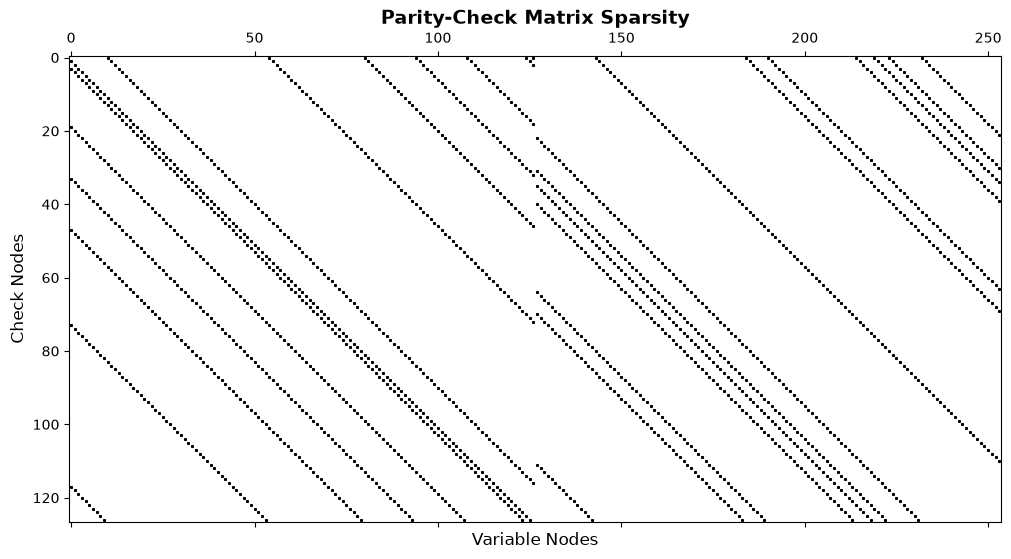

Saved Figure 2 to: Check_Node_Intersection_Spectrum.png


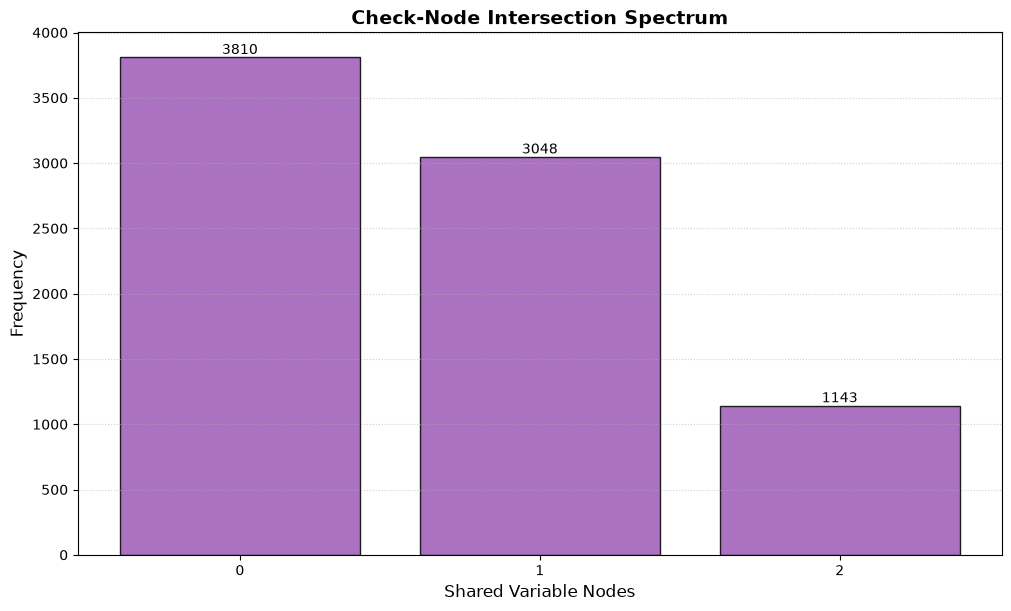

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# CONFIG & COLOR THEME
# =============================================================================
C_MATRIX = "black"      # Matrix plot in black and white
C_AUX = "#9B59B6"       # Original purple theme for intersection spectrum
r, W = 127, 14
seed = 42

# =============================================================================
# 1. LOAD OR REGENERATE MATRIX H
# =============================================================================
h_path = "../Research_Runs_QCMDPC/QCMDPC_RBGNN_N254_Research_20260912_094545/Phase_1_Topology/H_master.npy"

if os.path.exists(h_path):
    H = np.load(h_path)
    print(f"Successfully loaded existing H matrix from {h_path}")
else:
    print("Artifact not found. Regenerating Phase 1 H matrix...")
    rng = np.random.default_rng(seed)
    
    def generate_circulant_block(size, weight, generator):
        first_row = np.zeros(size, dtype=np.uint8)
        first_row[generator.choice(size, size=weight, replace=False)] = 1
        return np.array([np.roll(first_row, i) for i in range(size)])
    
    H0 = generate_circulant_block(r, W // 2, rng)
    H1 = generate_circulant_block(r, W // 2, rng)
    H = np.hstack((H0, H1))

# =============================================================================
# 2. FIGURE 1: PARITY-CHECK MATRIX SPARSITY
# =============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax1.spy(H, markersize=1.2, color=C_MATRIX)
ax1.set_title("Parity-Check Matrix Sparsity", fontweight="bold", fontsize=14)
ax1.set_xlabel("Variable Nodes", fontsize=12)
ax1.set_ylabel("Check Nodes", fontsize=12)

fig1_path = "Parity_Check_Matrix_Sparsity.png"
fig1.savefig(fig1_path, dpi=300, bbox_inches="tight")
print(f"Saved Figure 1 to: {fig1_path}")
plt.show()

# =============================================================================
# 3. FIGURE 2: CHECK-NODE INTERSECTION SPECTRUM
# =============================================================================
# Calculate variable 4-cycle participation (overlaps)
A = H.astype(np.int64) @ H.astype(np.int64).T
np.fill_diagonal(A, 0)
upper_triangle = A[np.triu_indices_from(A, k=1)]
counts = np.bincount(upper_triangle.astype(int))

fig2, ax2 = plt.subplots(figsize=(10, 6), constrained_layout=True)
bars = ax2.bar(
    np.arange(len(counts)), 
    counts, 
    color=C_AUX, 
    edgecolor="black", 
    alpha=0.85
)
ax2.set_title("Check-Node Intersection Spectrum", fontweight="bold", fontsize=14)
ax2.set_xlabel("Shared Variable Nodes", fontsize=12)
ax2.set_ylabel("Frequency", fontsize=12)
ax2.set_xticks(np.arange(len(counts)))
ax2.grid(axis="y", linestyle=":", alpha=0.6)

# Add value labels on top of the bars for clarity
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax2.text(
            bar.get_x() + bar.get_width() / 2, 
            height, 
            f'{int(height)}', 
            ha='center', va='bottom', fontsize=10
        )

fig2_path = "Check_Node_Intersection_Spectrum.png"
fig2.savefig(fig2_path, dpi=300, bbox_inches="tight")
print(f"Saved Figure 2 to: {fig2_path}")
plt.show()